# Transformacija podataka

Dataset na kome će biti demonstrirane tehnike transformacije podataka je dostupan [ovde](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset).

## Opis odabranog dataset-a (Bank Marketing)

Bank Marketing dataset sadrži podatke o marketinškoj kampanji jedne finansijske institucije. Cilj kampanje bio je da se klijentima ponudi otvaranje depozitnog računa, a podaci obuhvataju demografske informacije o klijentima, njihove finansijske karakteristike, kao i detalje o samoj kampanji.  
Glavni zadatak u analizi ovog skupa podataka jeste da se na osnovu dostupnih atributa predvidi da li će klijent prihvatiti ponudu banke (ciljna promenljiva **deposit**). Dataset je pogodan za demonstraciju različitih tehnika predobrade podataka, jer sadrži i numeričke i kategoričke atribute, kao i binarne kolone.

- **age** – starost klijenta (numerički atribut)  
- **job** – zanimanje klijenta (kategorički atribut)  
- **marital** – bračni status (kategorički atribut)  
- **education** – nivo obrazovanja (kategorički atribut)  
- **default** – da li klijent ima kredit u kašnjenju (binarno: yes/no)  
- **balance** – prosečan godišnji balans na računu (numerički atribut)  
- **housing** – da li klijent ima stambeni kredit (binarno: yes/no)  
- **loan** – da li klijent ima lični kredit (binarno: yes/no)  
- **contact** – tip kontakta tokom kampanje (kategorički atribut, npr. cellular, telephone)  
- **day** – dan u mesecu kada je kontakt ostvaren (numerički atribut)  
- **month** – mesec kada je kontakt ostvaren (kategorički atribut)  
- **duration** – trajanje poslednjeg kontakta u sekundama (numerički atribut)  
- **campaign** – broj kontakata tokom kampanje za klijenta (numerički atribut)  
- **pdays** – broj dana od poslednjeg kontakta u prethodnoj kampanji (numerički atribut; -1 znači da nije bilo kontakta)  
- **previous** – broj kontakata pre ove kampanje (numerički atribut)  
- **poutcome** – ishod prethodne kampanje (kategorički atribut: success, failure, other)  
- **deposit** – ciljna promenljiva: da li je klijent prihvatio ponudu (binarno: yes/no)  

## Import potrebnih biblioteka

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler, MinMaxScaler, MaxAbsScaler, Normalizer
import warnings
from sklearn.exceptions import ConvergenceWarning
from category_encoders import BinaryEncoder, CountEncoder, TargetEncoder
from sklearn.preprocessing import PowerTransformer, QuantileTransformer, KBinsDiscretizer, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor

In [3]:
sns.set_theme(context='notebook', palette='pastel')
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Učitavanje podataka

In [4]:
data = pd.read_csv('bank.csv')
print(f"Podaci sadrže {data.shape[0]} redova i {data.shape[1]} kolona.")

Podaci sadrže 11162 redova i 17 kolona.


## Pregled i analiza podataka

In [5]:
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [7]:
print("Nedostajuće vrednosti po kolonama:")
print(data.isnull().sum())

Nedostajuće vrednosti po kolonama:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


In [8]:
duplicates = data.duplicated().sum()
print(f"Broj dupliranih redova: {duplicates}")

Broj dupliranih redova: 0


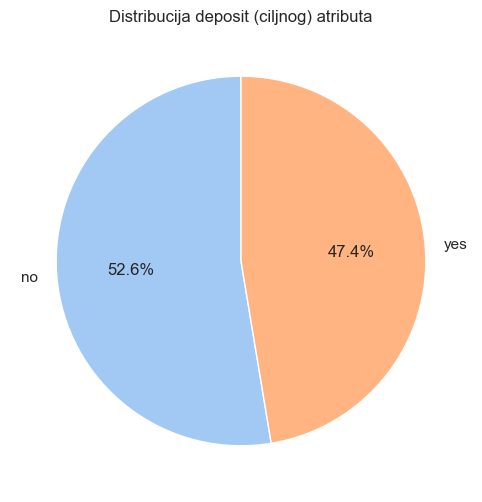

Distribucija klase: deposit
no     5873
yes    5289
Name: count, dtype: int64


In [9]:
deposit_distribution = data['deposit'].value_counts()
plt.figure(figsize=(8, 6))
deposit_distribution.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('Distribucija deposit (ciljnog) atributa')
plt.ylabel('')
plt.show()

print(f"Distribucija klase: {deposit_distribution}")

Nema nedostajućih vrednosti niti duplikata.

In [10]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


In [113]:
categorical_columns = data.select_dtypes(include='object').columns.tolist()
print(categorical_columns)

numerical_columns = data.select_dtypes(exclude=['object']).columns.tolist()
print(numerical_columns)

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


## Vizualizacija podataka

### Vizualizacija numeričkih atributa

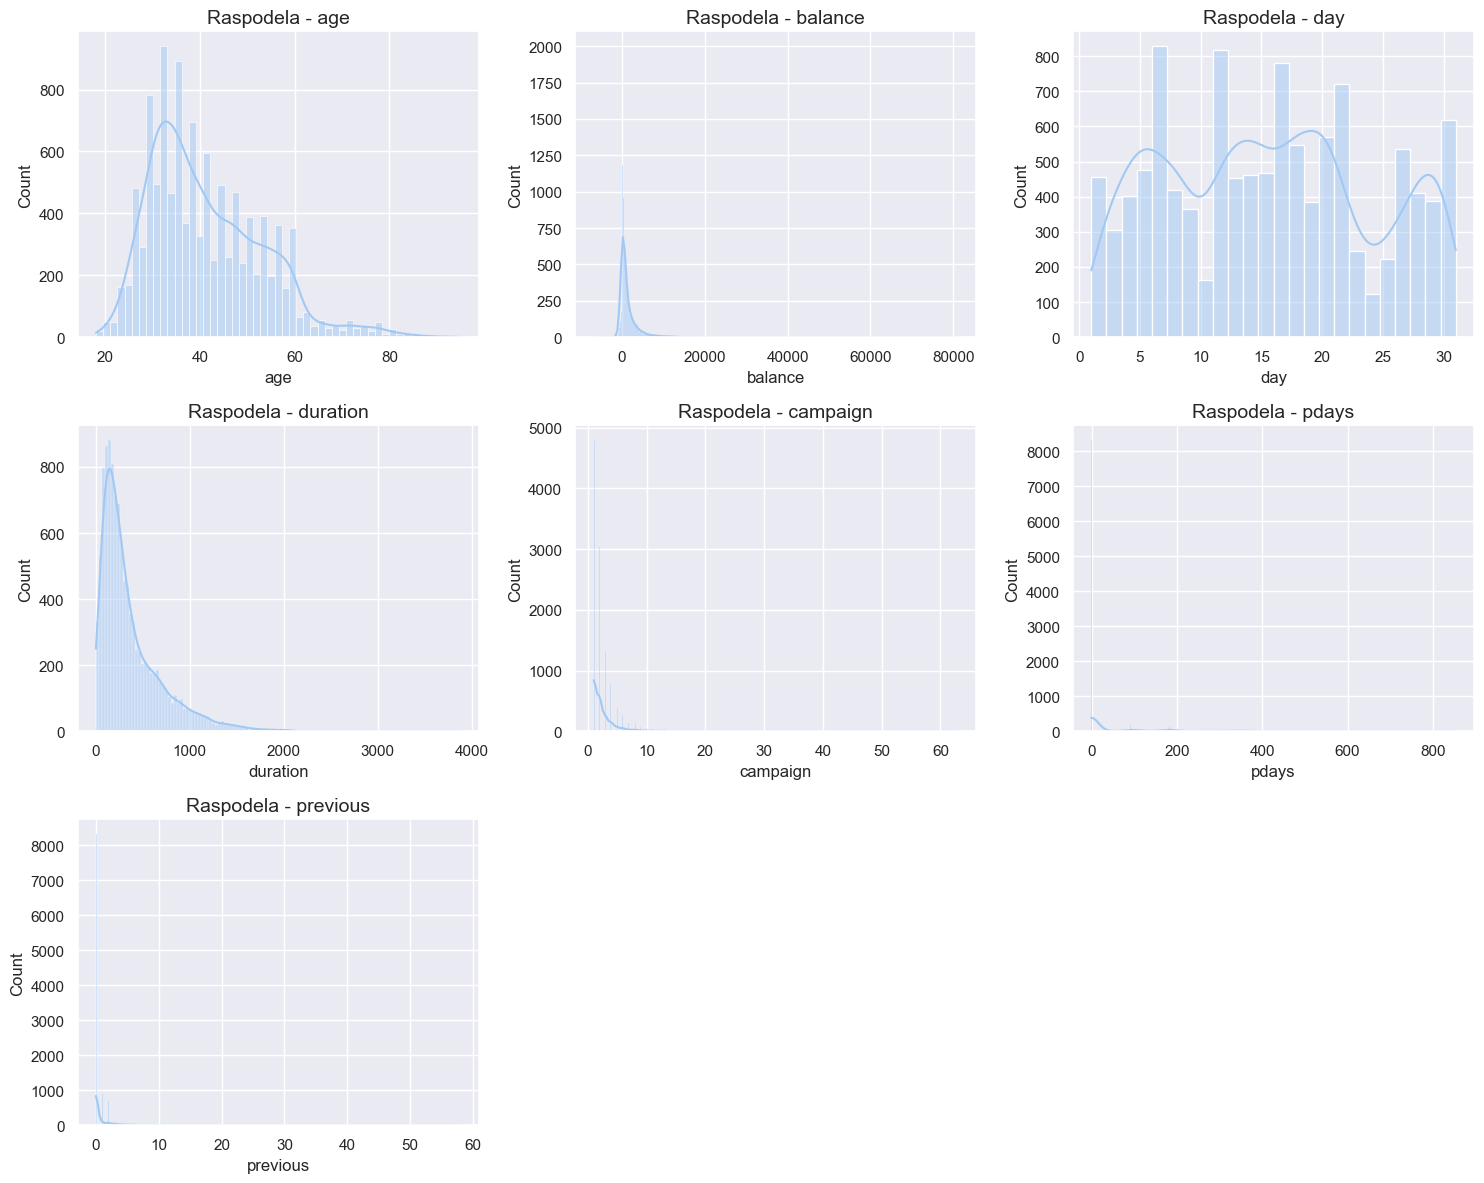

In [115]:
def visualize_numerical_features(data, num_columns, cols=3):
    n = len(num_columns)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(cols * 5, rows * 4))

    if n == 1:
        sns.histplot(data[num_columns[0]], kde=True)
        plt.title(f'Raspodela - {num_columns[0]}', fontsize=14)
    else:
        for i, column in enumerate(num_columns, 1):
            plt.subplot(rows, cols, i)
            sns.histplot(data[column], kde=True)
            plt.title(f'Raspodela - {column}', fontsize=14)

    plt.tight_layout()
    plt.show()

visualize_numerical_features(data, numerical_columns)

### Vizuelizacija kategoričkih atributa

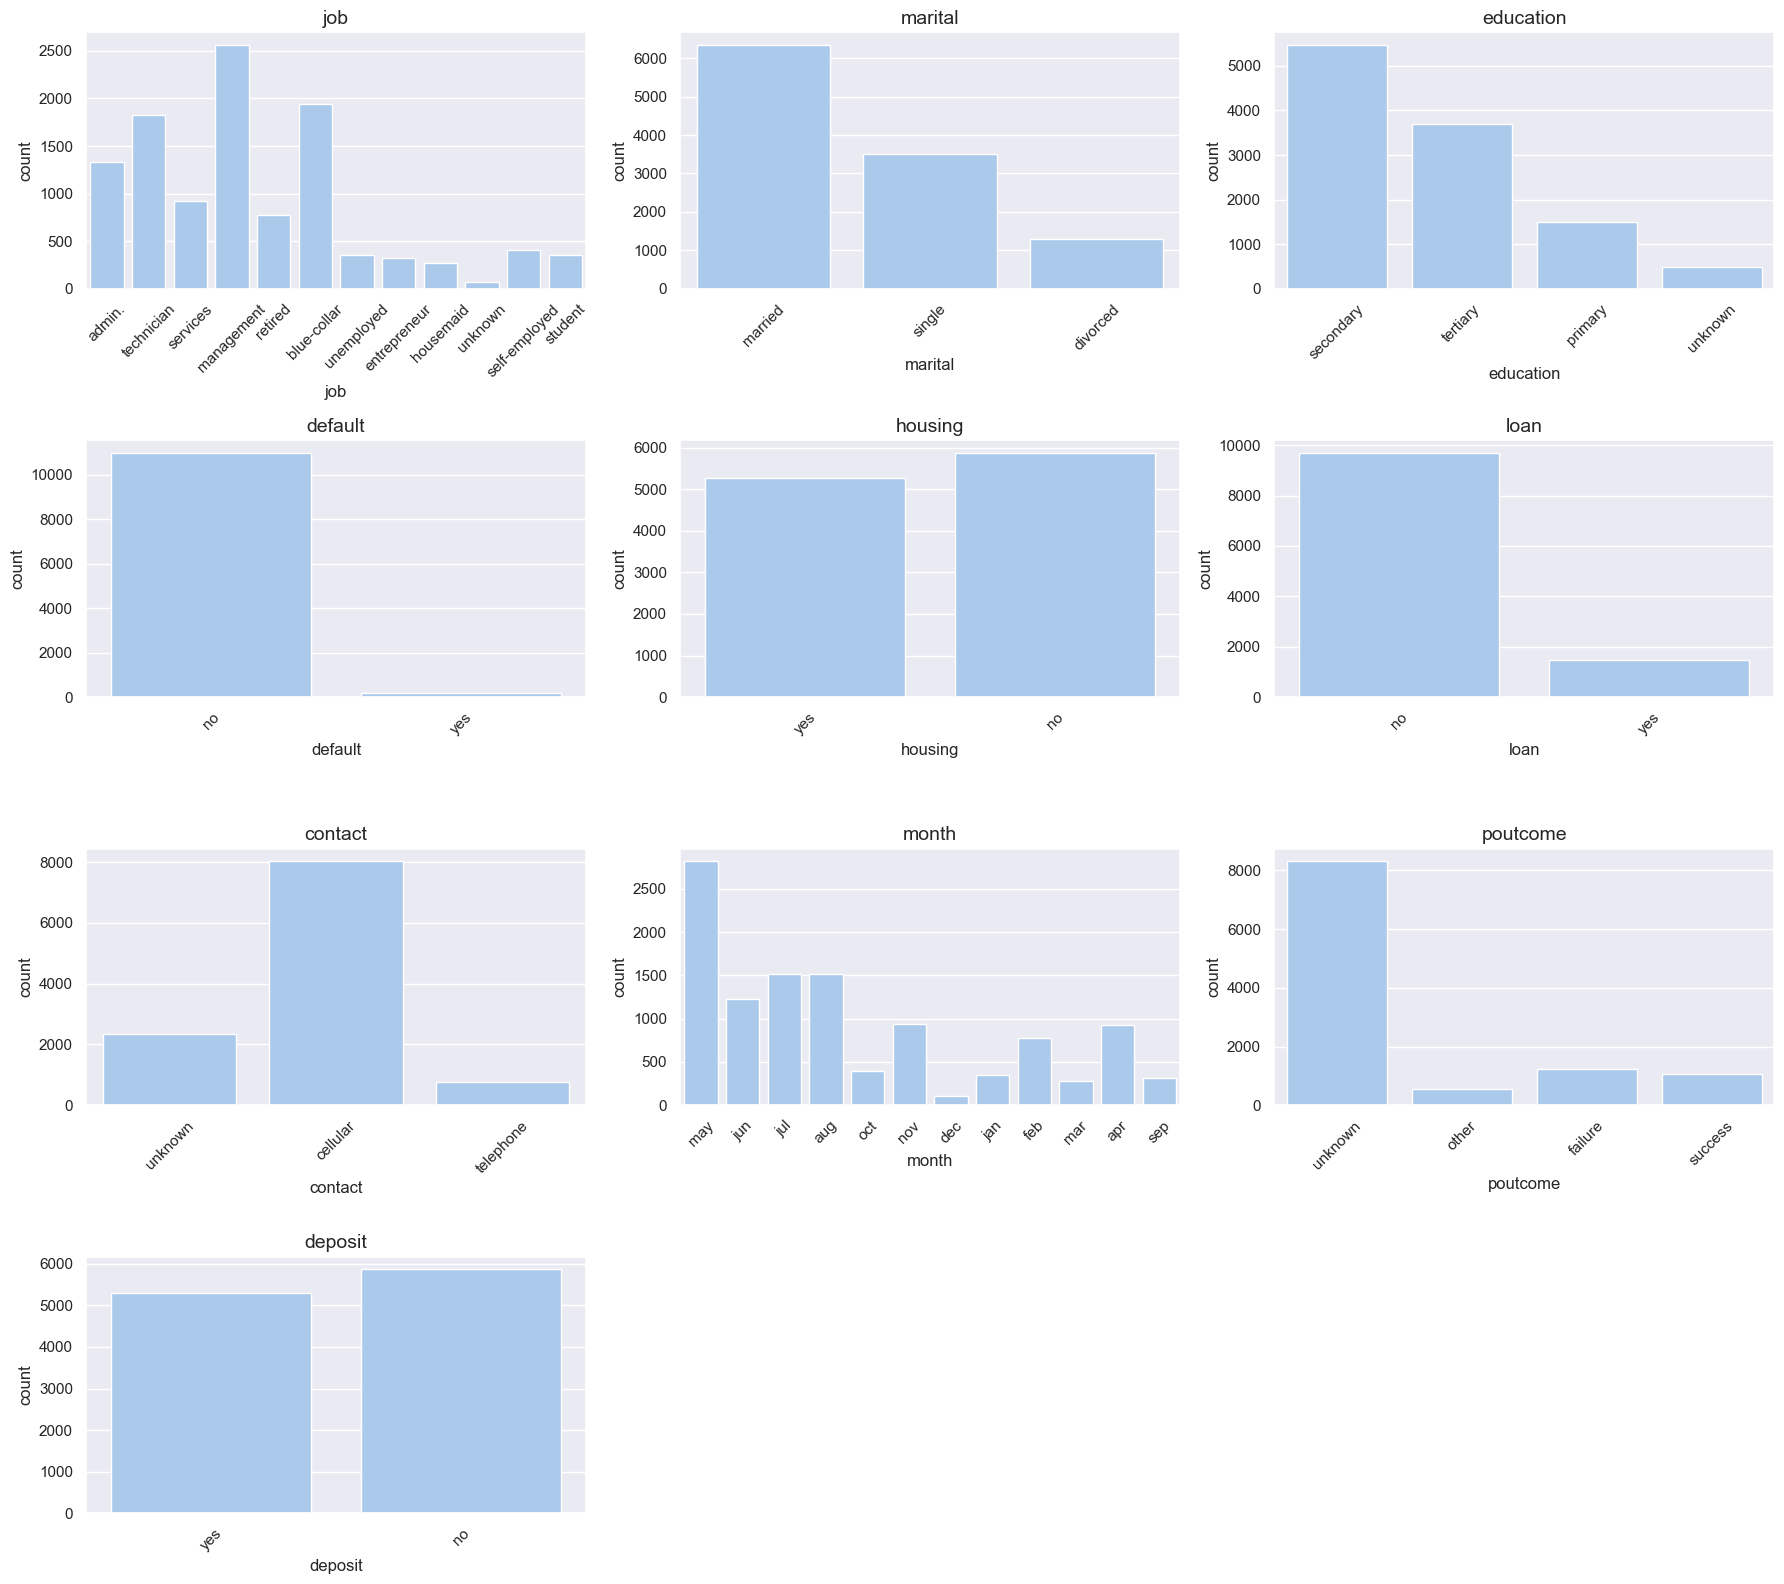

In [116]:
def visualize_categorical_features(data):
    n = len(categorical_columns)
    cols = 3
    rows = math.ceil(n / cols)

    plt.figure(figsize=(cols * 6, rows * 4))
    for i, column in enumerate(categorical_columns, 1):
        plt.subplot(rows, cols, i)
        sns.countplot(x=column, data=data)
        plt.title(f'{column}', fontsize=14)
        plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

visualize_categorical_features(data)

## Odabir modela za klasifikaciju

Za evaluaciju su odabrana tri modela: logistička regresija kao linearna metoda osetljiva na transformacije podataka, *Random Forest* kao metoda zasnovana na stablima koja je robusna na skaliranje i promenu raspodele, i SVM sa RBF kernelom kao metoda koja je posebno osetljiva na skalu podataka.

In [117]:
def calculate_metrics(y_test, y_pred):
    return  {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, average="macro"),
        "recall": recall_score(y_test, y_pred, average="macro"),
        "f1": f1_score(y_test, y_pred, average="macro")
    }

def run_logistic_regression(X_train, y_train, X_test, y_test):
    model = LogisticRegression(max_iter=10000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model, calculate_metrics(y_test, y_pred)

def run_random_forest(X_train, y_train, X_test, y_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model, calculate_metrics(y_test, y_pred)

def run_svm(X_train, y_train, X_test, y_test):
    model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model, calculate_metrics(y_test, y_pred)

def combine_results(lr_metrics, rf_metrics, svm_metrics):
    results = {
        "Logistic Regression": lr_metrics,
        "Random Forest": rf_metrics,
        "SVM (RBF)": svm_metrics,
    }
    df = pd.DataFrame(results).T
    df.index.name = "Model"
    return df

## Podela dataset-a na X i y

In [118]:
X = data.drop('deposit', axis=1)

# klasa 'yes' se mapira u 1, klasa 'no' u 0 i to se neće menjati do kraja projekta
y = data['deposit'].map({'yes': 1, 'no': 0})

## Baseline modeli za enkodiranje podataka

Za baseline modele minimalno je potrebno izvršiti neku tehniku enkodiranja, jer modeli ne mogu da rade sa kategoričkim atributima direktno. Zbog toga će biti izvršeno *Label* enkodiranje jer je jednostavno i ne povećava dimenzionalnost dataset-a. Ovakvi baseline modeli će biti korišćeni samo za poređenje tehnika enkodiranja kategoričkih atributa, a onda kada se utvrdi najbolja tehnika enkodiranja, biće uspostavljeni novi baseline modeli za poređenje ostalih tehnika (skaliranje, promena raspodele itd).

In [119]:
X_label_encoded = X.copy()

for col in X_label_encoded.select_dtypes(include='object').columns:
    le = LabelEncoder()
    X_label_encoded[col] = le.fit_transform(X_label_encoded[col])

X_train, X_test, y_train, y_test = train_test_split(
    X_label_encoded, y, test_size=0.2, random_state=42, stratify=y
)

In [120]:
_, lr_label_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_label_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_label_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_label_metrics, rf_label_metrics, svm_label_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.796686,0.796551,0.795326,0.795752
Random Forest,0.852665,0.852630,0.853600,0.852558
SVM (RBF),0.735334,0.739438,0.730817,0.731167


## Enkodiranje kategoričkih atributa

In [121]:
for col in categorical_columns:
    unique_vals = data[col].unique()
    print(f"Kolona: {col}")
    print(f"Broj jedinstvenih vrednosti: {len(unique_vals)}")
    print(f"Jedinstvene vrednosti: {unique_vals}")
    print()

Kolona: job
Broj jedinstvenih vrednosti: 12
Jedinstvene vrednosti: ['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student']

Kolona: marital
Broj jedinstvenih vrednosti: 3
Jedinstvene vrednosti: ['married' 'single' 'divorced']

Kolona: education
Broj jedinstvenih vrednosti: 4
Jedinstvene vrednosti: ['secondary' 'tertiary' 'primary' 'unknown']

Kolona: default
Broj jedinstvenih vrednosti: 2
Jedinstvene vrednosti: ['no' 'yes']

Kolona: housing
Broj jedinstvenih vrednosti: 2
Jedinstvene vrednosti: ['yes' 'no']

Kolona: loan
Broj jedinstvenih vrednosti: 2
Jedinstvene vrednosti: ['no' 'yes']

Kolona: contact
Broj jedinstvenih vrednosti: 3
Jedinstvene vrednosti: ['unknown' 'cellular' 'telephone']

Kolona: month
Broj jedinstvenih vrednosti: 12
Jedinstvene vrednosti: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

Kolona: poutcome
Broj jedinstvenih vrednosti: 4
Jedinstvene vr

Nominalni atributi su ***job***, ***marital***, ***default***, ***housing***, ***loan***, ***contact***, ***poutcome*** i ***deposit***, dok su ***education*** i ***month*** ordinalni.

### *One-Hot* + ordinalno enkodiranje

Za kolone ***education*** i ***month*** će biti korišćeno samo ordinalno enkodiranje jer jedino ima smisla. U ovom koraku za nominalne atribute će se koristiti *One-Hot* enkodiranje. Nedostatak je to što će nastati puno novih kolona za atribute sa puno različitih vrednosti.

In [122]:
ordinal_cols = ["education", "month"]
nominal_cols = ["job", "marital", "default", "housing", "loan", "contact", "poutcome"]

education_mapping = {
    "primary": 1,
    "secondary": 2,
    "tertiary": 3,
    "unknown": 0
}
X["education"] = X["education"].map(education_mapping)

month_mapping = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
    "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12
}
X["month"] = X["month"].map(month_mapping)

In [123]:
X_one_hot_encoded = pd.get_dummies(X[nominal_cols])

X_final = pd.concat([X.drop(columns=nominal_cols), X_one_hot_encoded], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_one_hot_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_one_hot_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_one_hot_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_one_hot_metrics, rf_one_hot_metrics, svm_one_hot_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.801612,0.802135,0.799725,0.800400
Random Forest,0.847291,0.847170,0.848117,0.847165
SVM (RBF),0.735334,0.739438,0.730817,0.731167


*One-Hot* enkodiranje je dalo približno iste rezultate kao i *Label* za sve modele.

### Binarno enkodiranje

Ovde će za nominalne atribute biti iskorišćeno binarno enkodiranje umesto *One-Hot*.

In [124]:
X_bin = X.copy()

# Mapiranje yes/no kolona u jednu binarnu kolonu
binary_cols = ["default", "housing", "loan"]
for col in binary_cols:
    X_bin[col] = X_bin[col].map({"yes": 1, "no": 0})

# BinaryEncoder za nominalne sa više kategorija
nominal_cols = ["job", "marital", "contact", "poutcome"]
encoder = BinaryEncoder(cols=nominal_cols)
X_bin_encoded = encoder.fit_transform(X_bin)

X_train, X_test, y_train, y_test = train_test_split(
    X_bin_encoded, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_binary_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_binary_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_binary_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_binary_metrics, rf_binary_metrics, svm_binary_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802508,0.803890,0.800105,0.800974
Random Forest,0.852665,0.852884,0.853835,0.852591
SVM (RBF),0.735334,0.739438,0.730817,0.731167


Rezultati su opet slični kao baseline.

### Frekventno (*count*) enkodiranje

Za frekventno i *Target* enkodiranje je bitno da se *fit*-uju na trening skupu, a onda primene na test skup kako ne bi došlo do curenja podataka.

In [125]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

nominal_cols = ["job", "marital", "default", "housing", "loan", "contact", "poutcome"]
encoder = CountEncoder(cols=nominal_cols)
X_train_enc = encoder.fit_transform(X_train)
X_test_enc = encoder.transform(X_test)

_, lr_frequency_metrics = run_logistic_regression(X_train_enc, y_train, X_test_enc, y_test)
_, rf_frequency_metrics = run_random_forest(X_train_enc, y_train, X_test_enc, y_test)
_, svm_frequency_metrics = run_svm(X_train_enc, y_train, X_test_enc, y_test)
display(combine_results(lr_frequency_metrics, rf_frequency_metrics, svm_frequency_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.777877,0.778484,0.775666,0.776342
Random Forest,0.856247,0.856849,0.857710,0.856206
SVM (RBF),0.765786,0.766144,0.763612,0.764220


U ovom slučaju, logistička regresija je dala malo manju tačnost (za $2\%$), a SVM veću (za $3\%$).

### *Target* enkodiranje

In [126]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

encoder = TargetEncoder(cols=nominal_cols)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_test_enc = encoder.transform(X_test)

_, lr_target_metrics = run_logistic_regression(X_train_enc, y_train, X_test_enc, y_test)
_, rf_target_metrics = run_random_forest(X_train_enc, y_train, X_test_enc, y_test)
_, svm_target_metrics = run_svm(X_train_enc, y_train, X_test_enc, y_test)
display(combine_results(lr_target_metrics, rf_target_metrics, svm_target_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.797134,0.797674,0.795187,0.795866
Random Forest,0.853560,0.854161,0.855016,0.853518
SVM (RBF),0.735334,0.739438,0.730817,0.731167


Rezultati su približno isti kao baseline.

### Poređenje rezultata

In [200]:
encodings = [
    ("Label (baseline)", lr_label_metrics, rf_label_metrics, svm_label_metrics),
    ("One-Hot", lr_one_hot_metrics, rf_one_hot_metrics, svm_one_hot_metrics),
    ("Frequency", lr_frequency_metrics, rf_frequency_metrics, svm_frequency_metrics),
    ("Binary", lr_binary_metrics, rf_binary_metrics, svm_binary_metrics),
    ("Target", lr_target_metrics, rf_target_metrics, svm_target_metrics),
]

def compare_metrics(metrics):
    results = []
    for name, lr_metrics, rf_metrics, svm_metrics in metrics:
        results.append({
            "Technique": name,
            "LogReg Accuracy": lr_metrics["accuracy"],
            "LogReg F1": lr_metrics["f1"],
            "RF Accuracy": rf_metrics["accuracy"],
            "RF F1": rf_metrics["f1"],
            "SVM Accuracy": svm_metrics["accuracy"],
            "SVM F1": svm_metrics["f1"],
        })
    
    df_results = pd.DataFrame(results)
    display(df_results)

compare_metrics(encodings)

,Technique,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Label (baseline),0.796686,0.795752,0.852665,0.852558,0.735334,0.731167
1,One-Hot,0.801612,0.800400,0.847291,0.847165,0.735334,0.731167
2,Frequency,0.777877,0.776342,0.856247,0.856206,0.765786,0.764220
3,Binary,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
4,Target,0.797134,0.795866,0.853560,0.853518,0.735334,0.731167


Logistička regresija postiže najbolje rezultate sa binarnim enkodiranjem, a *Random Forest* i SVM sa frekventnim enkodiranjem. Za novi baseline će biti korišćeno binarno enkodiranje jer olakšava interpretabilnost, a i nemamo puno kolona sa puno različitih vrednosti da bismo koristili frekventno enkodiranje (jedina takva je ***job***, ali ona binarnim enkodiranjem može da se predstavi pomoću 4 kolone, što nije puno).

## Baseline modeli za ostale tehnike

In [128]:
binary_cols = ["default", "housing", "loan"]
for col in binary_cols:
    X[col] = X[col].map({"yes": 1, "no": 0})

nominal_cols = ["job", "marital", "contact", "poutcome"]
encoder = BinaryEncoder(cols=nominal_cols)
X = encoder.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_baseline_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_baseline_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_baseline_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802508,0.803890,0.800105,0.800974
Random Forest,0.852665,0.852884,0.853835,0.852591
SVM (RBF),0.735334,0.739438,0.730817,0.731167


## Skaliranje podataka

Skaliranje podataka se primenjuje samo na numeričkim kolonama.

In [129]:
numeric_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

### *Min-Max* skaliranje

In [130]:
scaler = MinMaxScaler()

X_train_minmax = X_train.copy()
X_test_minmax = X_test.copy()
X_train_minmax[numeric_cols] = scaler.fit_transform(X_train_minmax[numeric_cols])
X_test_minmax[numeric_cols] = scaler.transform(X_test_minmax[numeric_cols])

_, lr_minmax_metrics = run_logistic_regression(X_train_minmax, y_train, X_test_minmax, y_test)
_, rf_minmax_metrics = run_random_forest(X_train_minmax, y_train, X_test_minmax, y_test)
_, svm_minmax_metrics = run_svm(X_train_minmax, y_train, X_test_minmax, y_test)
display(combine_results(lr_minmax_metrics, rf_minmax_metrics, svm_minmax_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.801612,0.803255,0.799066,0.799975
Random Forest,0.853112,0.853361,0.854308,0.853042
SVM (RBF),0.794447,0.796061,0.791834,0.792717


Ukupni rezultati su se poboljšali jedino za SVM što je i očekivano jer je on osetljiv na skalu podataka.

### Standardizacija (*Z-score* skaliranje)

In [131]:
scaler = StandardScaler()

X_train_standard = X_train.copy()
X_test_standard = X_test.copy()
X_train_standard[numeric_cols] = scaler.fit_transform(X_train_standard[numeric_cols])
X_test_standard[numeric_cols] = scaler.transform(X_test_standard[numeric_cols])

_, lr_standard_metrics = run_logistic_regression(X_train_standard, y_train, X_test_standard, y_test)
_, rf_standard_metrics = run_random_forest(X_train_standard, y_train, X_test_standard, y_test)
_, svm_standard_metrics = run_svm(X_train_standard, y_train, X_test_standard, y_test)
display(combine_results(lr_standard_metrics, rf_standard_metrics, svm_standard_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802508,0.803890,0.800105,0.800974
Random Forest,0.852665,0.852884,0.853835,0.852591
SVM (RBF),0.830721,0.830227,0.830820,0.830427


Ukupni rezultati su se poboljšali jedino za SVM, i bolji su i od baseline i od *Min-Max* skaliranja.

### Robustno skaliranje

In [132]:
scaler = RobustScaler()

X_train_robust = X_train.copy()
X_test_robust = X_test.copy()
X_train_robust[numeric_cols] = scaler.fit_transform(X_train_robust[numeric_cols])
X_test_robust[numeric_cols] = scaler.transform(X_test_robust[numeric_cols])

_, lr_robust_metrics = run_logistic_regression(X_train_robust, y_train, X_test_robust, y_test)
_, rf_robust_metrics = run_random_forest(X_train_robust, y_train, X_test_robust, y_test)
_, svm_robust_metrics = run_svm(X_train_robust, y_train, X_test_robust, y_test)
display(combine_results(lr_robust_metrics, rf_robust_metrics, svm_robust_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802508,0.803890,0.800105,0.800974
Random Forest,0.853112,0.853361,0.854308,0.853042
SVM (RBF),0.826691,0.826184,0.826331,0.826253


Ukupni rezultati su se poboljšali jedino za SVM i vrlo malo su slabiji (manje od $1\%$) u odnosu na slučaj kada je korišćena standardizacija.

### *Max-Abs* skaliranje

In [133]:
scaler = MaxAbsScaler()

X_train_maxabs = X_train.copy()
X_test_maxabs = X_test.copy()
X_train_maxabs[numeric_cols] = scaler.fit_transform(X_train_maxabs[numeric_cols])
X_test_maxabs[numeric_cols] = scaler.transform(X_test_maxabs[numeric_cols])

_, lr_maxabs_metrics = run_logistic_regression(X_train_maxabs, y_train, X_test_maxabs, y_test)
_, rf_maxabs_metrics = run_random_forest(X_train_maxabs, y_train, X_test_maxabs, y_test)
_, svm_maxabs_metrics = run_svm(X_train_maxabs, y_train, X_test_maxabs, y_test)
display(combine_results(lr_maxabs_metrics, rf_maxabs_metrics, svm_maxabs_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.801612,0.803161,0.799113,0.800008
Random Forest,0.852665,0.852942,0.853882,0.852596
SVM (RBF),0.793551,0.795150,0.790936,0.791814


Ukupni rezultati su se poboljšali jedino kod SVM u poređenju sa baseline i MinMax skaliranjem, a slabiji su u odnosu na standardizaciju i robustno skaliranje.

### Poređenje rezultata

In [134]:
scalers = [
    ("Baseline", lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics),
    ("Min-Max", lr_minmax_metrics, rf_minmax_metrics, svm_minmax_metrics),
    ("Standard", lr_standard_metrics, rf_standard_metrics, svm_standard_metrics),
    ("Robust", lr_robust_metrics, rf_robust_metrics, svm_robust_metrics),
    ("MaxAbs", lr_maxabs_metrics, rf_maxabs_metrics, svm_maxabs_metrics),
]

compare_metrics(scalers)

,Encoding,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Baseline,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
1,Min-Max,0.801612,0.799975,0.853112,0.853042,0.794447,0.792717
2,Standard,0.802508,0.800974,0.852665,0.852591,0.830721,0.830427
3,Robust,0.802508,0.800974,0.853112,0.853042,0.826691,0.826253
4,MaxAbs,0.801612,0.800008,0.852665,0.852596,0.793551,0.791814


Na logističku regresiju i *Random Forest* skaliranje nije značajno uticalo, dok je kod SVM‑a imalo efekta, pri čemu se standardizacija pokazala kao najbolja tehnika.

## Normalizacija

Normalizacija se odnosi na skaliranje pojedinačnih slogova (ne kolona), tako da njihova norma bude 1. Najčešće se koriste $L1$, $L2$ i $L \infty$ norme. U ovom primeru je korišćena $L2$ norma.

In [135]:
normalizer = Normalizer(norm='l2')

X_train_norm = X_train.copy()
X_test_norm = X_test.copy()

X_train_norm = normalizer.fit_transform(X_train)
X_test_norm = normalizer.transform(X_test)

_, lr_norm_metrics = run_logistic_regression(X_train_norm, y_train, X_test_norm, y_test)
_, rf_norm_metrics = run_random_forest(X_train_norm, y_train, X_test_norm, y_test)
_, svm_norm_metrics = run_svm(X_train_norm, y_train, X_test_norm, y_test)

In [136]:
normalizers = [
    ("Baseline", lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics),
    ("L2", lr_norm_metrics, rf_norm_metrics, svm_norm_metrics)
]

compare_metrics(normalizers)

,Encoding,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Baseline,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
1,L2,0.712047,0.710078,0.821317,0.821075,0.719660,0.718914


Rezultati su se nakon normalizacije pogoršali, što je donekle i očekivano jer je normalizacija korisna u algoritmima gde su bitni ugao ili kosinusna sličnost, kao što su klasifikacija teksta ili klasterizacija. U našem slučaju, SVM se najmanje pogoršao, *Random Forest* malo više, a Logistička Regresija najviše.

## Promena raspodele podataka

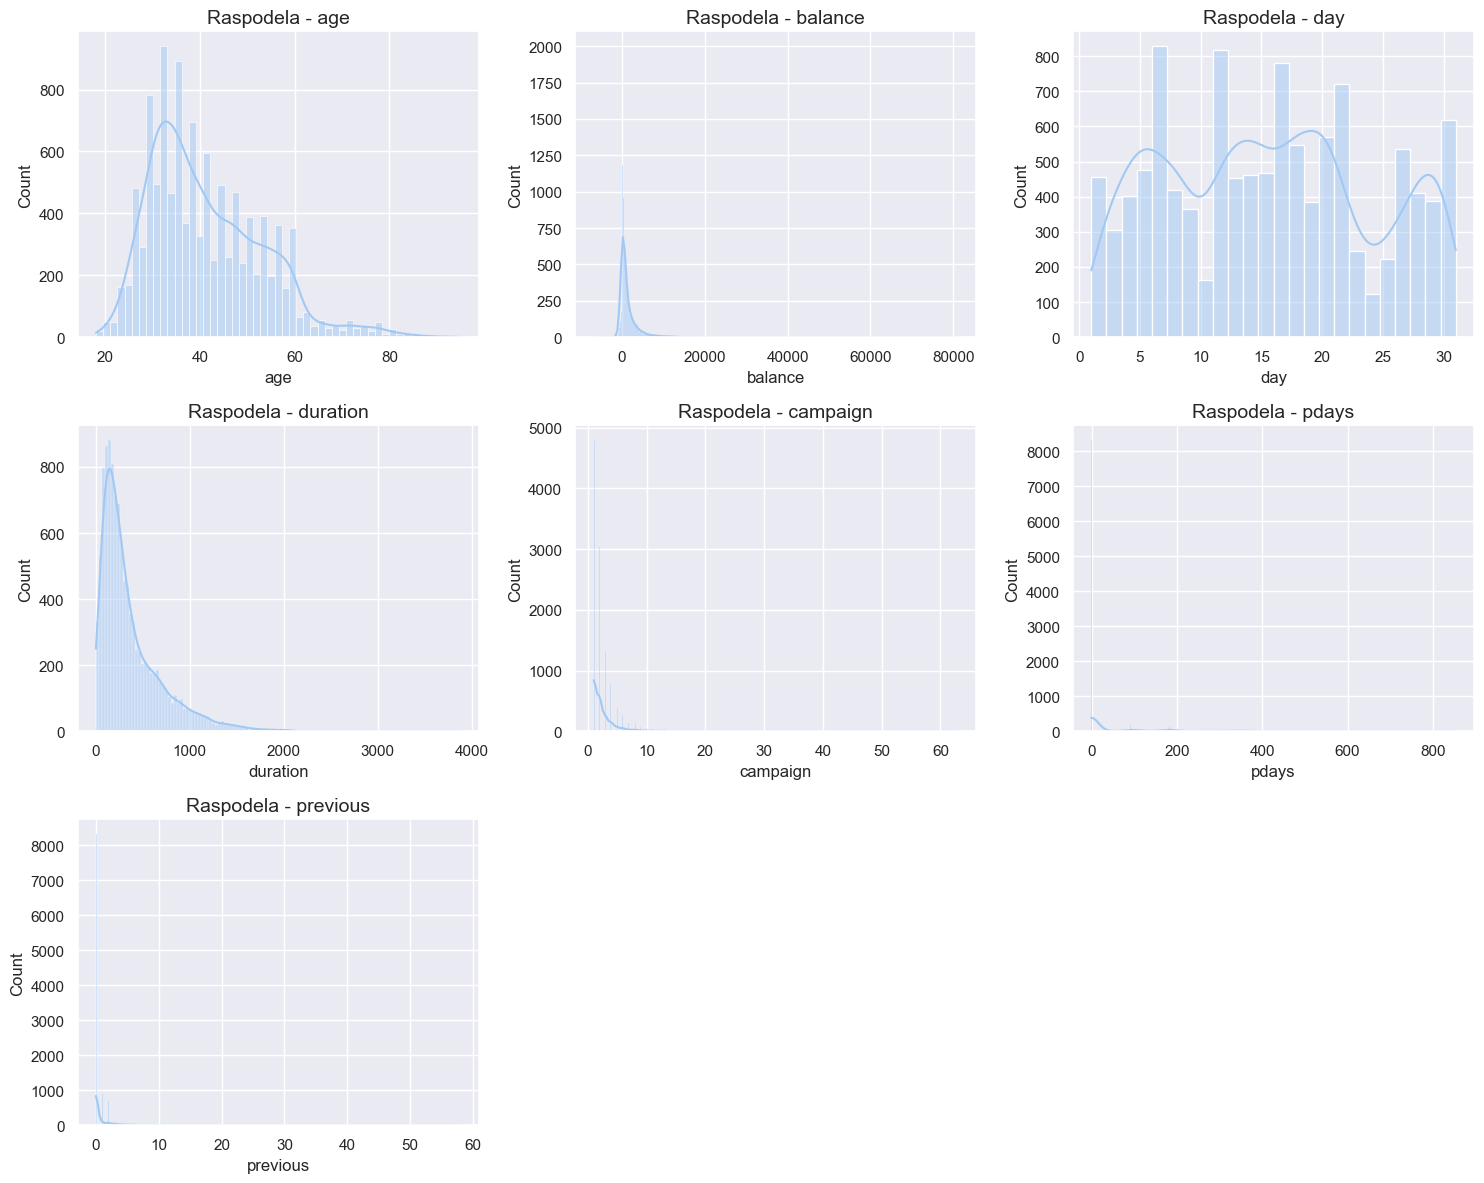

In [137]:
visualize_numerical_features(X, numeric_cols)

Računamo i *skewness* svake numeričke kolone:

In [138]:
df_skewness = X[numeric_cols].skew().to_frame(name='Skewness')
display(df_skewness)

,Skewness
age,0.862780
balance,8.224619
day,0.111330
duration,2.143695
campaign,5.545578
pdays,2.449986
previous,7.335298


Analizom prikazanih histograma i dobijenih vrednosti *skewness*-a, zaključujemo da su atributi ***balance***, ***duration***, ***campaign***, ***pdays*** i ***previous*** desno asimetrični (iskrivljeni) i nad njima će biti primenjivane transformacije za promenu raspodele opisane u teorijskom delu.

In [139]:
skewed_cols = ["balance", "duration", "campaign", "pdays", "previous"]

### Logaritamska transformacija

In [140]:
X_train_log = X_train.copy()
X_test_log = X_test.copy()

for col in skewed_cols:
    min_val = X[col].min()
    if min_val <= 0:
        shift = abs(min_val) + 1
    else:
        shift = 0
    X_train_log[col] = np.log(X_train_log[col] + shift)
    X_test_log[col] = np.log(X_test_log[col] + shift)

_, lr_log_metrics = run_logistic_regression(X_train_log, y_train, X_test_log, y_test)
_, rf_log_metrics = run_random_forest(X_train_log, y_train, X_test_log, y_test)
_, svm_log_metrics = run_svm(X_train_log, y_train, X_test_log, y_test)
display(combine_results(lr_log_metrics, rf_log_metrics, svm_log_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.805195,0.804649,0.805106,0.804819
Random Forest,0.853560,0.853898,0.854828,0.853498
SVM (RBF),0.801164,0.801781,0.802499,0.801110


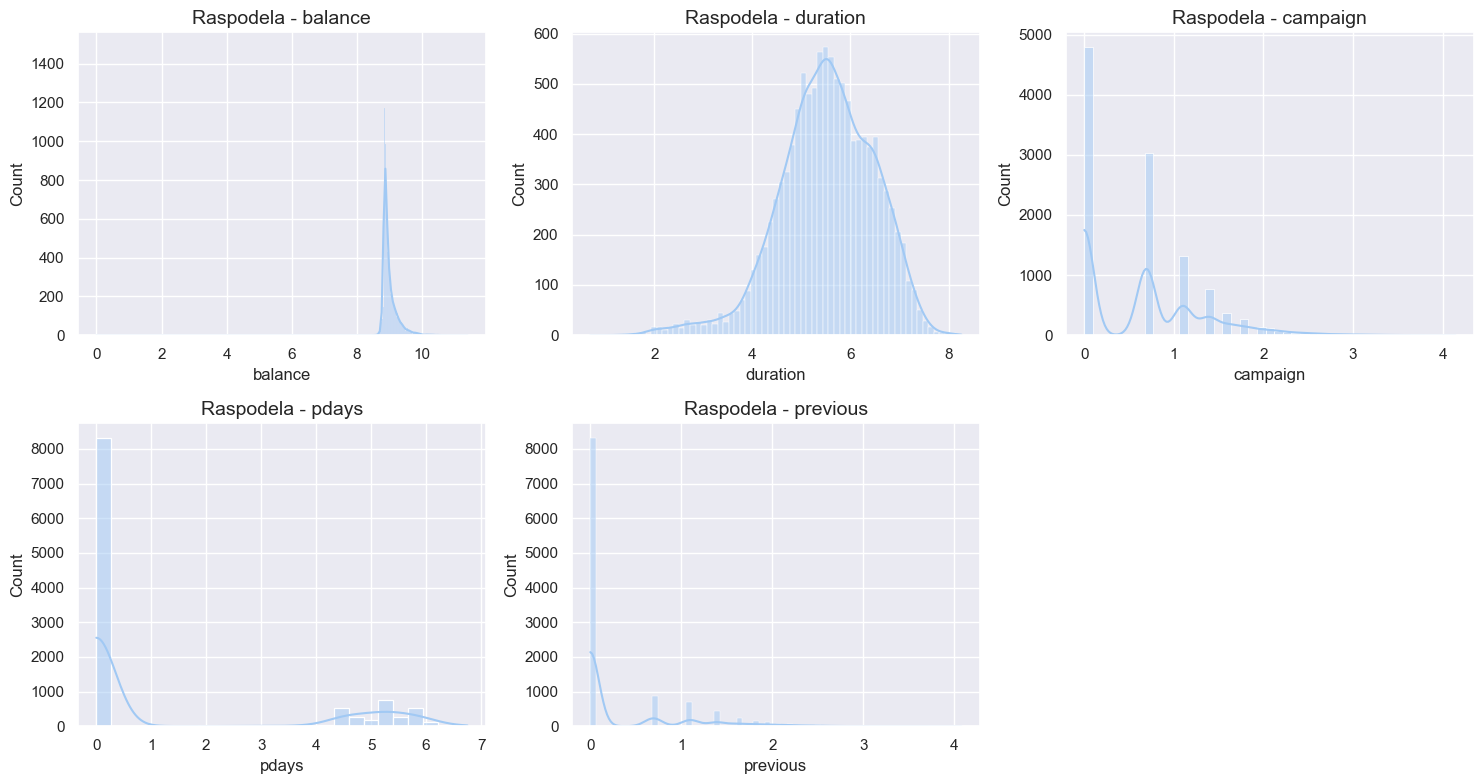

In [141]:
visualize_numerical_features(pd.concat([X_train_log, X_test_log], axis=0), skewed_cols)

Logaritamska transformacija nije toliko uspešna kada su podaci jako iskrivljeni u smislu da ne može da napravi normalnu raspodelu. Što se tiče samih modela, logistička regresija i *Random Forest* su ostali isti, a SVM je dao za 7% bolje rezultate.

### Eksponencijalna transformacija

Pošto su podaci desno iskrivljeni, eksponent treba da bude manji od $1$, tj. potrebno je primeniti korenovanje.

#### Kvadratni koren

In [142]:
X_train_root = X_train.copy()
X_test_root = X_test.copy()

for col in skewed_cols:
    min_val = X[col].min()
    if min_val <= 0:
        shift = abs(min_val) + 1
    else:
        shift = 0
    X_train_root[col] = np.power(X_train_root[col] + shift, 1/2)
    X_test_root[col] = np.power(X_test_root[col] + shift, 1/2)

_, lr_root_metrics = run_logistic_regression(X_train_root, y_train, X_test_root, y_test)
_, rf_root_metrics = run_random_forest(X_train_root, y_train, X_test_root, y_test)
_, svm_root_metrics = run_svm(X_train_root, y_train, X_test_root, y_test)
display(combine_results(lr_root_metrics, rf_root_metrics, svm_root_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.807434,0.807142,0.806386,0.806685
Random Forest,0.853112,0.853420,0.854355,0.853047
SVM (RBF),0.780564,0.779960,0.779960,0.779960


Samo SVM se poboljšao za 5%.

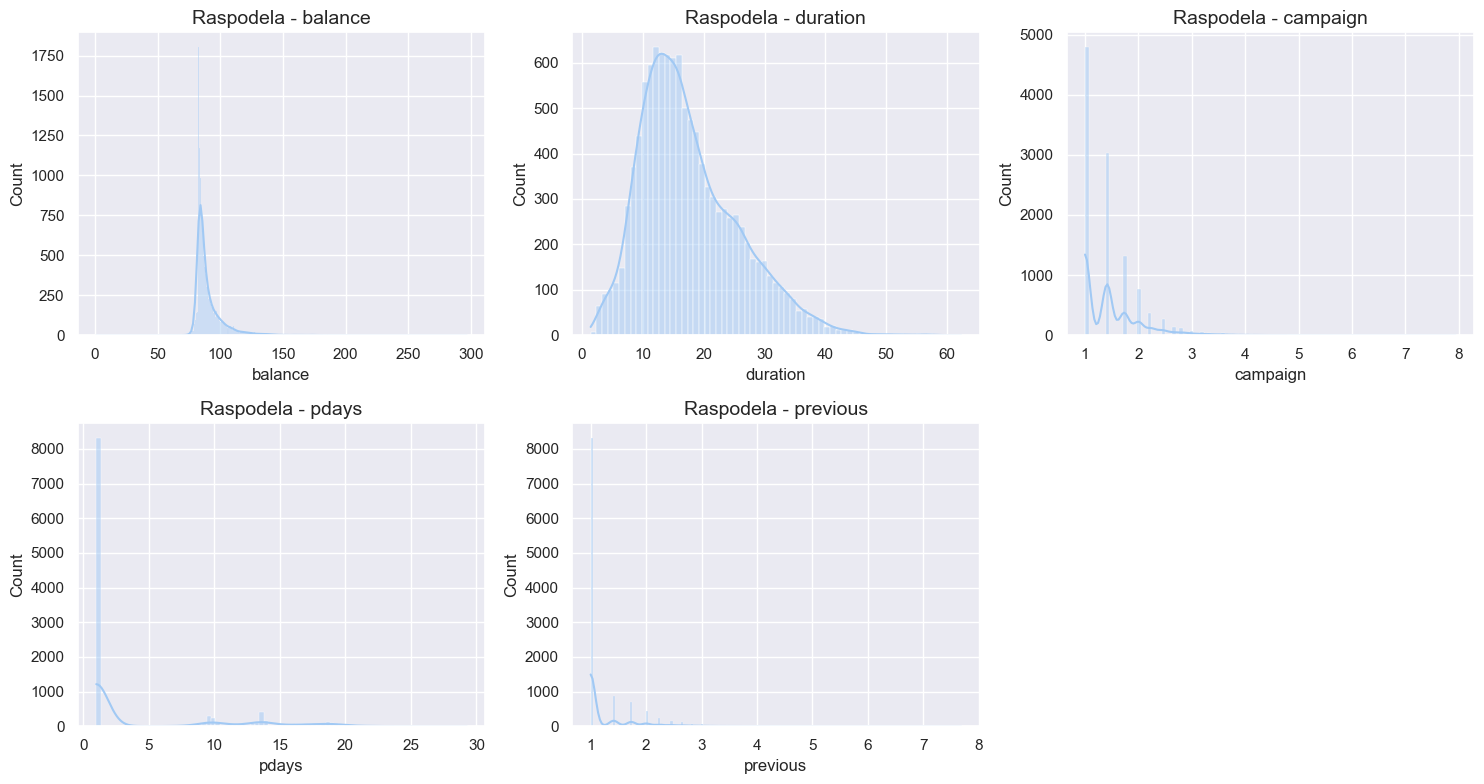

In [143]:
visualize_numerical_features(pd.concat([X_train_root, X_test_root], axis=0), skewed_cols)

#### Kubni koren

In [144]:
X_train_cuberoot = X_train.copy()
X_test_cuberoot = X_test.copy()

for col in skewed_cols:
    X_train_cuberoot[col] = np.cbrt(X_train_cuberoot[col])
    X_test_cuberoot[col] = np.cbrt(X_test_cuberoot[col])

_, lr_cuberoot_metrics = run_logistic_regression(X_train_cuberoot, y_train, X_test_cuberoot, y_test)
_, rf_cuberoot_metrics = run_random_forest(X_train_cuberoot, y_train, X_test_cuberoot, y_test)
_, svm_cuberoot_metrics = run_svm(X_train_cuberoot, y_train, X_test_cuberoot, y_test)
display(combine_results(lr_cuberoot_metrics, rf_cuberoot_metrics, svm_cuberoot_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.806538,0.806064,0.805817,0.805930
Random Forest,0.851769,0.852169,0.853078,0.851711
SVM (RBF),0.795790,0.795437,0.796169,0.795547


Samo SVM se poboljšao, malo više nego sa kvadratnim korenom (za 6% sada). Takođe, vidimo da ***balance*** i ***duration*** sada više liče na normalnu raspodelu.

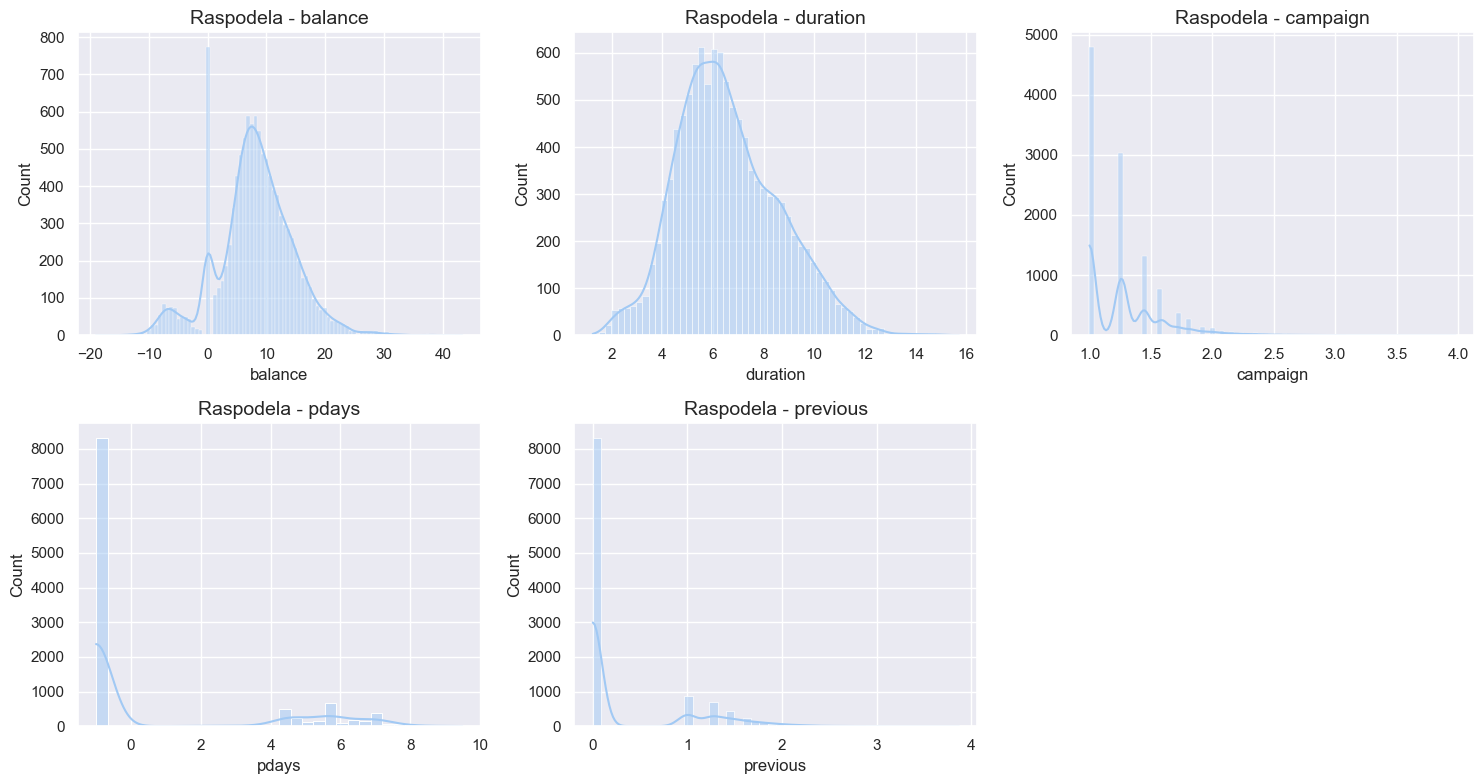

In [145]:
visualize_numerical_features(pd.concat([X_train_cuberoot, X_test_cuberoot], axis=0), skewed_cols)

### Box-Cox transformacija

In [146]:
X_train_boxcox = X_train.copy()
X_test_boxcox = X_test.copy()

for col in skewed_cols:
    min_val = X[col].min()
    if min_val <= 0:
        shift = abs(min_val) + 1
    else:
        shift = 0
        
    X_train_boxcox[col] = X_train_boxcox[col] + shift
    X_test_boxcox[col] = X_test_boxcox[col] + shift

pt_boxcox = PowerTransformer(method="box-cox")
X_train_boxcox[skewed_cols] = pt_boxcox.fit_transform(X_train_boxcox[skewed_cols])
X_test_boxcox[skewed_cols] = pt_boxcox.transform(X_test_boxcox[skewed_cols])

_, lr_boxcox_metrics = run_logistic_regression(X_train_boxcox, y_train, X_test_boxcox, y_test)
_, rf_boxcox_metrics = run_random_forest(X_train_boxcox, y_train, X_test_boxcox, y_test)
_, svm_boxcox_metrics = run_svm(X_train_boxcox, y_train, X_test_boxcox, y_test)
display(combine_results(lr_boxcox_metrics, rf_boxcox_metrics, svm_boxcox_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.805643,0.805082,0.805296,0.805178
Random Forest,0.853112,0.853481,0.854402,0.853053
SVM (RBF),0.800269,0.800304,0.801131,0.800138


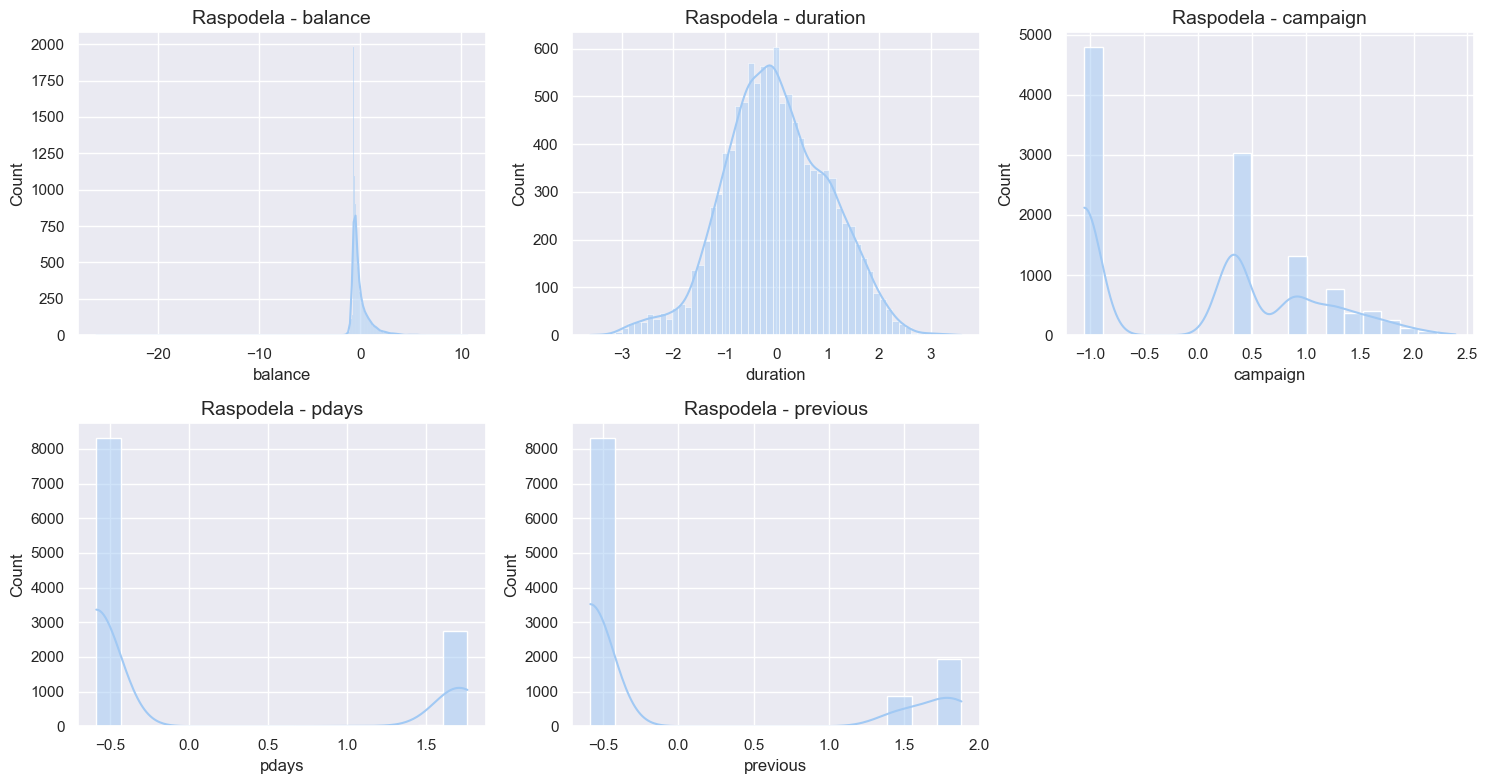

In [147]:
visualize_numerical_features(pd.concat([X_train_boxcox, X_test_boxcox], axis=0), skewed_cols)

*Box-Cox* transformacija je poboljšala tačnost SVM-a za 7%. Vidimo da postoji problem kod ***pdays*** i ***previous*** jer oni imaju bimodalnu raspodelu, pa *Box-Cox* transformacija nije mogla da napravi normalnu raspodelu kod njih.

### Yeo-Johnson transformacija

In [148]:
X_train_yeojohnson = X_train.copy()
X_test_yeojohnson = X_test.copy()

pt_yeojohnson = PowerTransformer(method="yeo-johnson")
X_train_yeojohnson[skewed_cols] = pt_yeojohnson.fit_transform(X_train_yeojohnson[skewed_cols])
X_test_yeojohnson[skewed_cols] = pt_yeojohnson.transform(X_test_yeojohnson[skewed_cols])

_, lr_yeojohnson_metrics = run_logistic_regression(X_train_yeojohnson, y_train, X_test_yeojohnson, y_test)
_, rf_yeojohnson_metrics = run_random_forest(X_train_yeojohnson, y_train, X_test_yeojohnson, y_test)
_, svm_yeojohnson_metrics = run_svm(X_train_yeojohnson, y_train, X_test_yeojohnson, y_test)
display(combine_results(lr_yeojohnson_metrics, rf_yeojohnson_metrics, svm_yeojohnson_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.803851,0.803302,0.803358,0.803330
Random Forest,0.853112,0.853481,0.854402,0.853053
SVM (RBF),0.800269,0.800629,0.801413,0.800188


Modeli postiže tačnost kao kod *Box-Cox* transformacije. Vidimo da su dobijene raspodele slične kao kod *Box-Cox* transformacije.

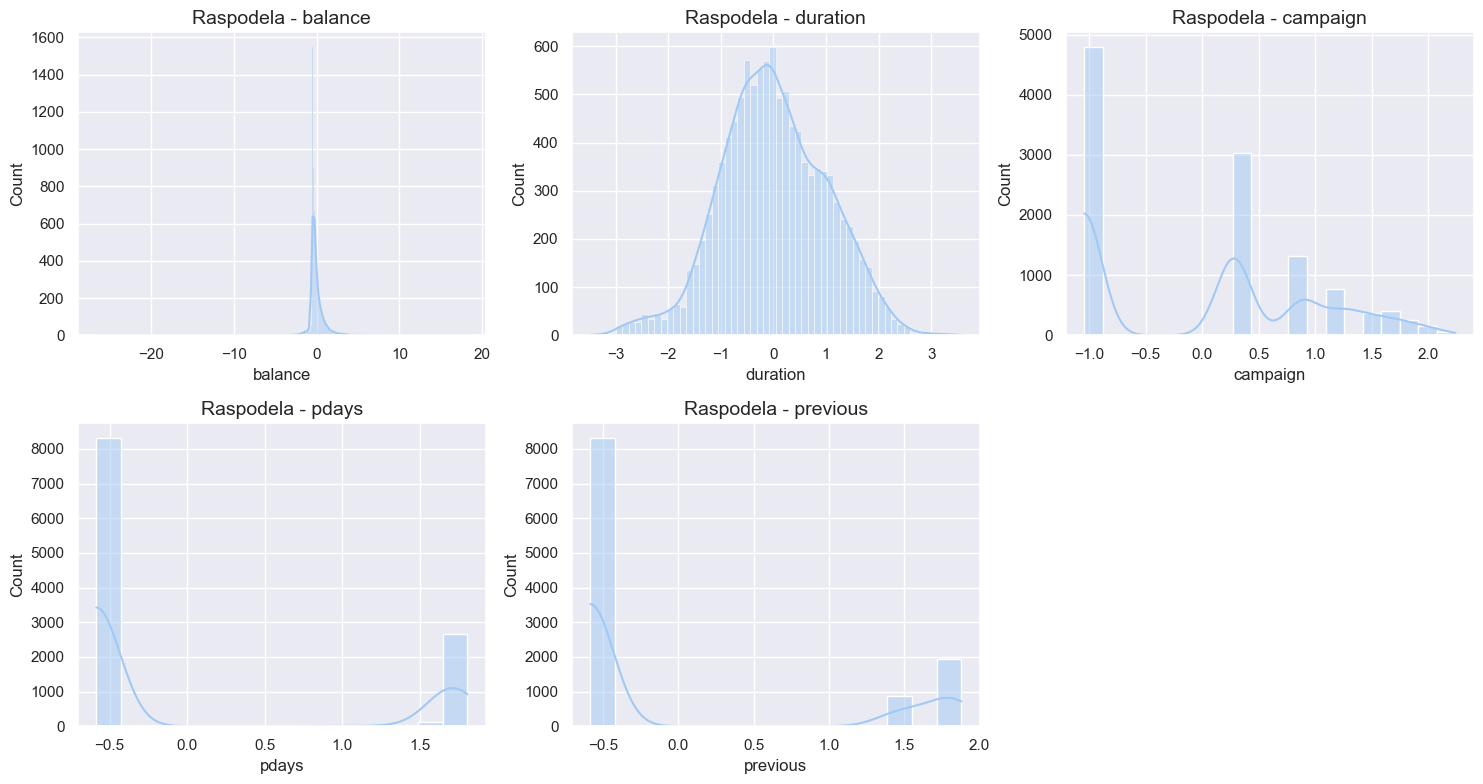

In [149]:
visualize_numerical_features(pd.concat([X_train_yeojohnson, X_test_yeojohnson], axis=0), skewed_cols)

### Kvantilna transformacija

#### Normalna raspodela

In [150]:
X_train_quantile_normal = X_train.copy()
X_test_quantile_normal = X_test.copy()

qt_normal = QuantileTransformer(output_distribution="normal", random_state=42)
X_train_quantile_normal[skewed_cols] = qt_normal.fit_transform(X_train_quantile_normal[skewed_cols])
X_test_quantile_normal[skewed_cols] = qt_normal.transform(X_test_quantile_normal[skewed_cols])

_, lr_quantile_normal_metrics = run_logistic_regression(X_train_quantile_normal, y_train, X_test_quantile_normal, y_test)
_, rf_quantile_normal_metrics = run_random_forest(X_train_quantile_normal, y_train, X_test_quantile_normal, y_test)
_, svm_quantile_normal_metrics = run_svm(X_train_quantile_normal, y_train, X_test_quantile_normal, y_test)
display(combine_results(lr_quantile_normal_metrics, rf_quantile_normal_metrics, svm_quantile_normal_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802956,0.802412,0.802884,0.802583
Random Forest,0.850873,0.851273,0.852180,0.850815
SVM (RBF),0.797582,0.797667,0.798483,0.797459


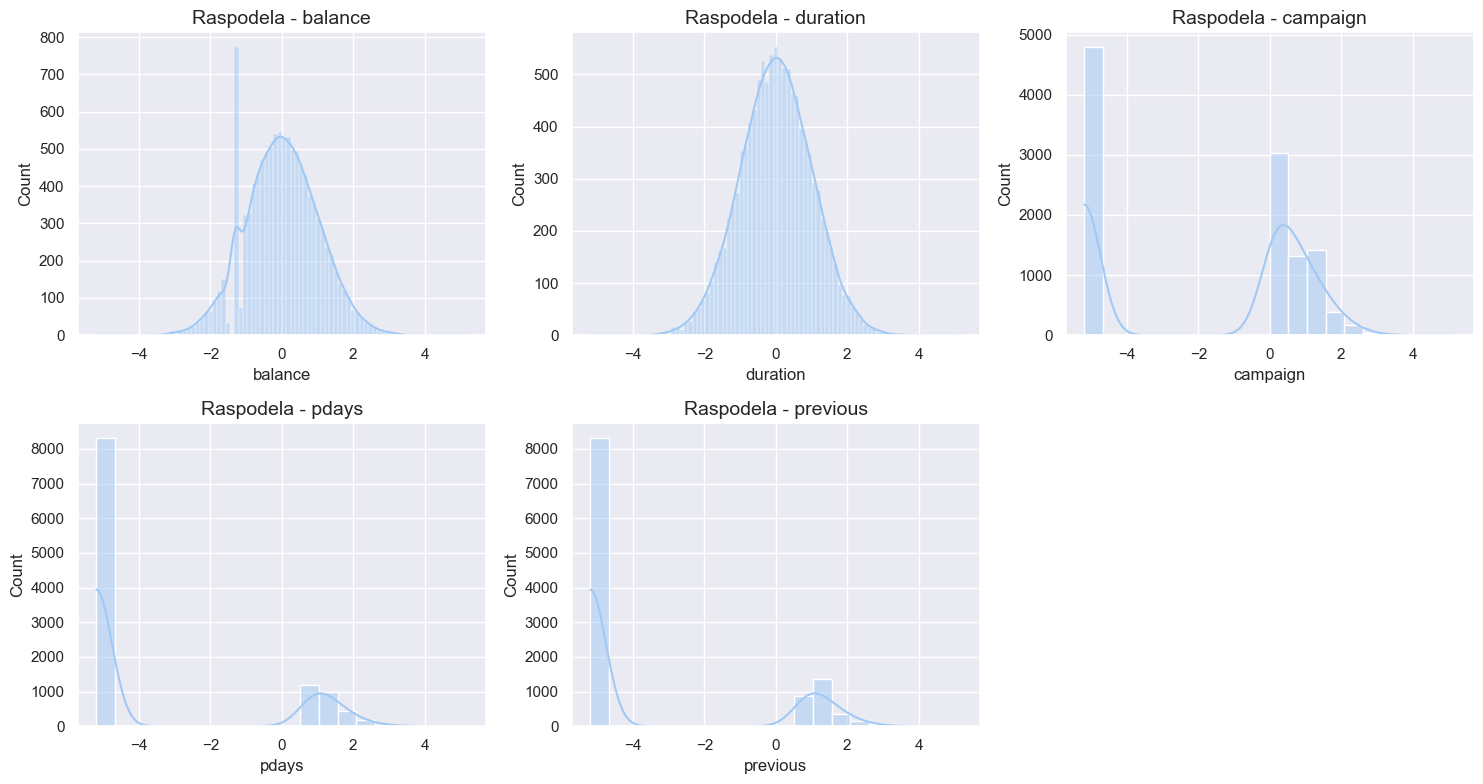

In [151]:
visualize_numerical_features(pd.concat([X_train_quantile_normal, X_test_quantile_normal], axis=0), skewed_cols)

Samo SVM je dao bolje rezultate u odnosu na baseline.

#### Uniformna raspodela

In [152]:
X_train_quantile_uniform = X_train.copy()
X_test_quantile_uniform = X_test.copy()

qt_uniform = QuantileTransformer(output_distribution="uniform", random_state=42)
X_train_quantile_uniform[skewed_cols] = qt_uniform.fit_transform(X_train_quantile_uniform[skewed_cols])
X_test_quantile_uniform[skewed_cols] = qt_uniform.transform(X_test_quantile_uniform[skewed_cols])

_, lr_quantile_uniform_metrics = run_logistic_regression(X_train_quantile_uniform, y_train, X_test_quantile_uniform, y_test)
_, rf_quantile_uniform_metrics = run_random_forest(X_train_quantile_uniform, y_train, X_test_quantile_uniform, y_test)
_, svm_quantile_uniform_metrics = run_svm(X_train_quantile_uniform, y_train, X_test_quantile_uniform, y_test)
display(combine_results(lr_quantile_uniform_metrics, rf_quantile_uniform_metrics, svm_quantile_uniform_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.798477,0.797939,0.798440,0.798112
Random Forest,0.853112,0.853544,0.854449,0.853058
SVM (RBF),0.729064,0.736521,0.723354,0.723089


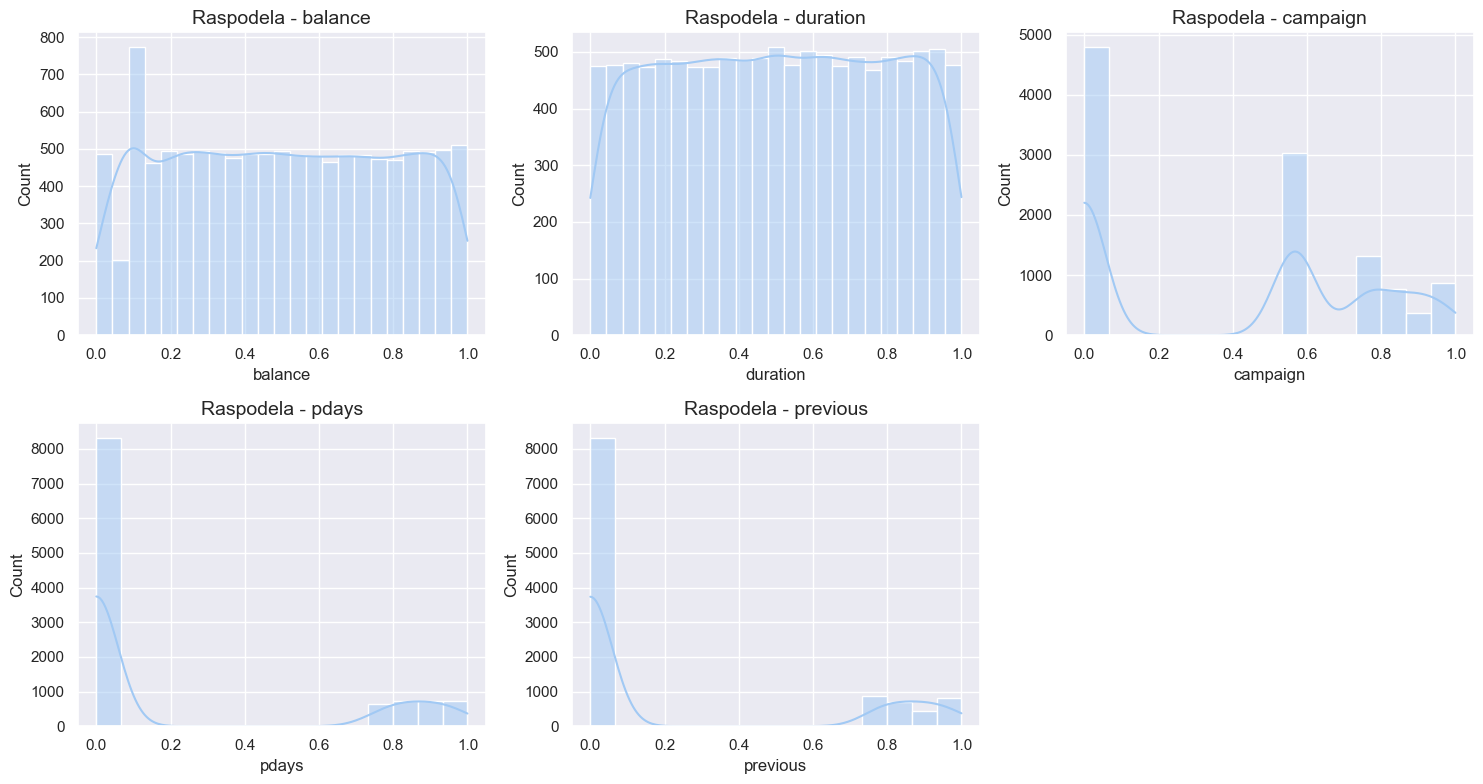

In [153]:
visualize_numerical_features(pd.concat([X_train_quantile_uniform, X_test_quantile_uniform], axis=0), skewed_cols)

Sada se tačnost logističke regresije i SVM-a smanjila za po $1\%$. Modeli bolje rade kada je raspodela normalna, a ne uniformna.

### Poređenje tehnika

In [154]:
transformers = [
    ("Baseline", lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics),
    ("Log", lr_log_metrics, rf_log_metrics, svm_log_metrics),
    ("Sqrt", lr_root_metrics, rf_root_metrics, svm_root_metrics),
    ("Cbrt", lr_cuberoot_metrics, rf_cuberoot_metrics, svm_cuberoot_metrics),
    ("BoxCox", lr_boxcox_metrics, rf_boxcox_metrics, svm_boxcox_metrics),
    ("YeoJohnson", lr_yeojohnson_metrics, rf_yeojohnson_metrics, svm_yeojohnson_metrics),
    ("QuantileNormal", lr_quantile_normal_metrics, rf_quantile_normal_metrics, svm_quantile_normal_metrics),
    ("QuantileUniform", lr_quantile_uniform_metrics, rf_quantile_uniform_metrics, svm_quantile_uniform_metrics)
]

compare_metrics(transformers)

,Encoding,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Baseline,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
1,Log,0.805195,0.804819,0.853560,0.853498,0.801164,0.801110
2,Sqrt,0.807434,0.806685,0.853112,0.853047,0.780564,0.779960
3,Cbrt,0.806538,0.805930,0.851769,0.851711,0.795790,0.795547
4,BoxCox,0.805643,0.805178,0.853112,0.853053,0.800269,0.800138
5,YeoJohnson,0.803851,0.803330,0.853112,0.853053,0.800269,0.800188
6,QuantileNormal,0.802956,0.802583,0.850873,0.850815,0.797582,0.797459
7,QuantileUniform,0.798477,0.798112,0.853112,0.853058,0.729064,0.723089


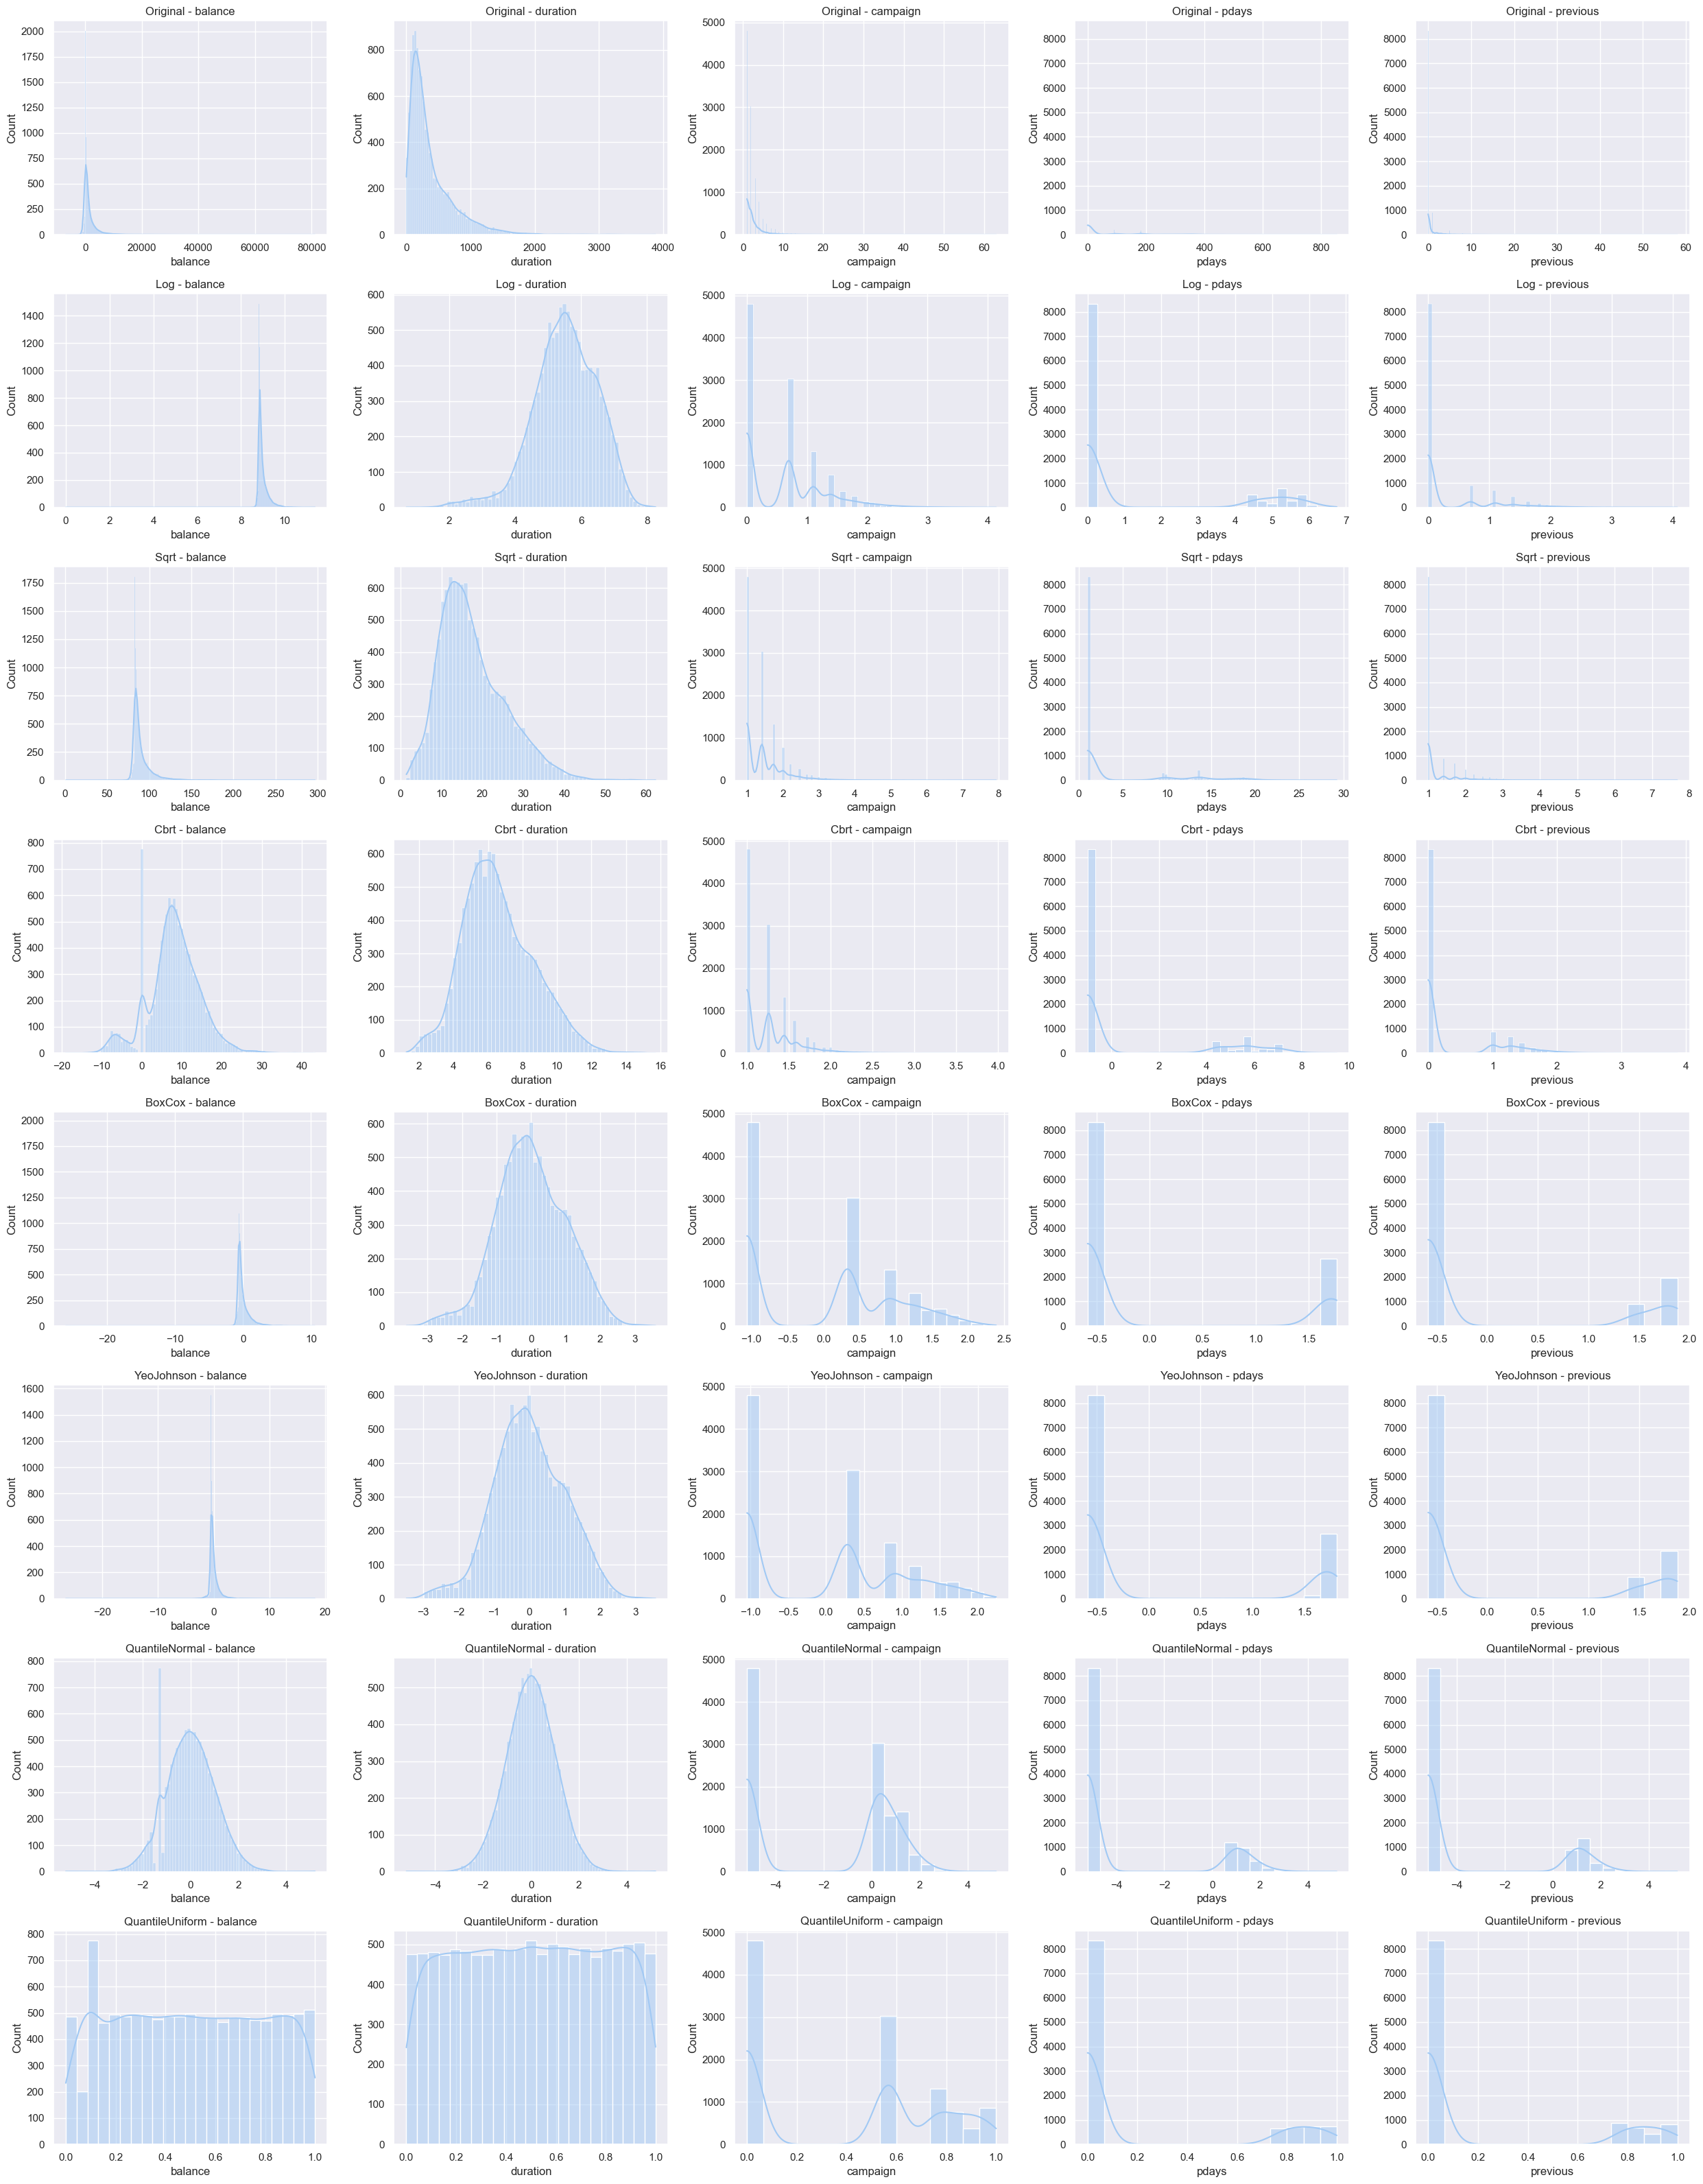

In [155]:
datasets = [
    ("Original", X),
    ("Log", pd.concat([X_train_log, X_test_log], axis=0)),
    ("Sqrt", pd.concat([X_train_root, X_test_root], axis=0)),
    ("Cbrt", pd.concat([X_train_cuberoot, X_test_cuberoot], axis=0)),
    ("BoxCox", pd.concat([X_train_boxcox, X_test_boxcox], axis=0)),
    ("YeoJohnson", pd.concat([X_train_yeojohnson, X_test_yeojohnson], axis=0)),
    ("QuantileNormal", pd.concat([X_train_quantile_normal, X_test_quantile_normal], axis=0)),
    ("QuantileUniform", pd.concat([X_train_quantile_uniform, X_test_quantile_uniform], axis=0))
]

num_columns = skewed_cols
cols = len(skewed_cols)
rows = len(datasets)

plt.figure(figsize=(cols * 5, rows * 4))

plot_index = 1
for name, df in datasets:
    for col in num_columns:
        plt.subplot(rows, cols, plot_index)
        sns.histplot(df[col], kde=True)
        plt.title(f'{name} - {col}', fontsize=12)
        plot_index += 1

plt.tight_layout()
plt.show()

## Diskretizacija podataka

Diskretizacija se vrši na numeričkim kontinualnim atributima. U našem slučaju, ***age*** je dobar kandidat za diskretizaciju, pa će na njemu biti demonstrirane različite tehnike diskretizacije.

### Podela na intervale jednake širine

In [156]:
disc_uniform = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform')

X_train_age_uniform = X_train.copy()
X_test_age_uniform = X_test.copy()

X_train_age_uniform[['age']] = disc_uniform.fit_transform(X_train[['age']])
X_test_age_uniform[['age']] = disc_uniform.transform(X_test[['age']])

_, lr_age_uniform_metrics = run_logistic_regression(X_train_age_uniform, y_train, X_test_age_uniform, y_test)
_, rf_age_uniform_metrics = run_random_forest(X_train_age_uniform, y_train, X_test_age_uniform, y_test)
_, svm_age_uniform_metrics = run_svm(X_train_age_uniform, y_train, X_test_age_uniform, y_test)
display(combine_results(lr_age_uniform_metrics, rf_age_uniform_metrics, svm_age_uniform_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802060,0.803392,0.799680,0.800539
Random Forest,0.853112,0.853148,0.854120,0.853017
SVM (RBF),0.734438,0.738506,0.729919,0.730257


Performanse modela se nisu značajno promenile.

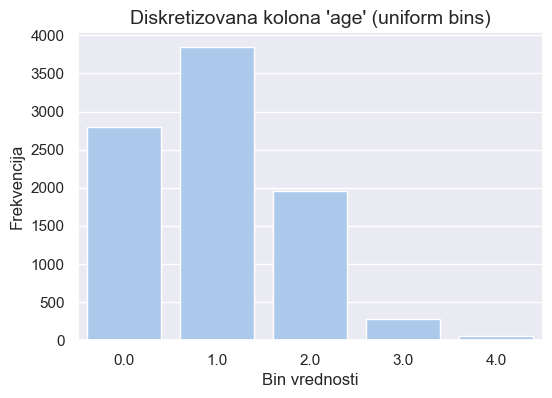

In [157]:
plt.figure(figsize=(6,4))
sns.countplot(x='age', data=X_train_age_uniform)
plt.title("Diskretizovana kolona 'age' (uniform bins)", fontsize=14)
plt.xlabel("Bin vrednosti")
plt.ylabel("Frekvencija")
plt.show()

### Podela na intervale jednake učestalosti

In [158]:
disc_quantile = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile', quantile_method='averaged_inverted_cdf')

X_train_age_quantile = X_train.copy()
X_test_age_quantile = X_test.copy()

X_train_age_quantile[['age']] = disc_quantile.fit_transform(X_train[['age']])
X_test_age_quantile[['age']] = disc_quantile.transform(X_test[['age']])

_, lr_age_quantile_metrics = run_logistic_regression(X_train_age_quantile, y_train, X_test_age_quantile, y_test)
_, rf_age_quantile_metrics = run_random_forest(X_train_age_quantile, y_train, X_test_age_quantile, y_test)
_, svm_age_quantile_metrics = run_svm(X_train_age_quantile, y_train, X_test_age_quantile, y_test)
display(combine_results(lr_age_quantile_metrics, rf_age_quantile_metrics, svm_age_quantile_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.801164,0.802152,0.798970,0.799760
Random Forest,0.852217,0.852354,0.853316,0.852133
SVM (RBF),0.734438,0.738506,0.729919,0.730257


Rezultati se nisu značajno promenili.

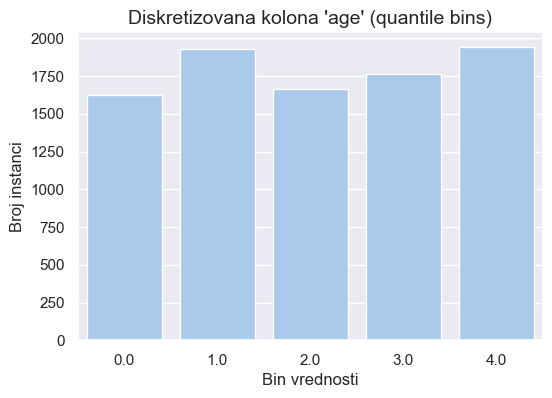

In [159]:
plt.figure(figsize=(6,4))
sns.countplot(x='age', data=X_train_age_quantile)
plt.title("Diskretizovana kolona 'age' (quantile bins)", fontsize=14)
plt.xlabel("Bin vrednosti")
plt.ylabel("Broj instanci")
plt.show()

### Diskretizacija pomoću klasterizacije (K-means)

In [160]:
disc_kmeans = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='kmeans')

X_train_age_kmeans = X_train.copy()
X_test_age_kmeans = X_test.copy()

X_train_age_kmeans[['age']] = disc_kmeans.fit_transform(X_train[['age']])
X_test_age_kmeans[['age']] = disc_kmeans.transform(X_test[['age']])

_, lr_age_kmeans_metrics = run_logistic_regression(X_train_age_kmeans, y_train, X_test_age_kmeans, y_test)
_, rf_age_kmeans_metrics = run_random_forest(X_train_age_kmeans, y_train, X_test_age_kmeans, y_test)
_, svm_age_kmeans_metrics = run_svm(X_train_age_kmeans, y_train, X_test_age_kmeans, y_test)
display(combine_results(lr_age_kmeans_metrics, rf_age_kmeans_metrics, svm_age_kmeans_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.801612,0.803070,0.799160,0.800040
Random Forest,0.845499,0.845421,0.846368,0.845380
SVM (RBF),0.734438,0.738506,0.729919,0.730257


Sada se tačnost *Random Forest* modela smanjila za oko $1\%$.

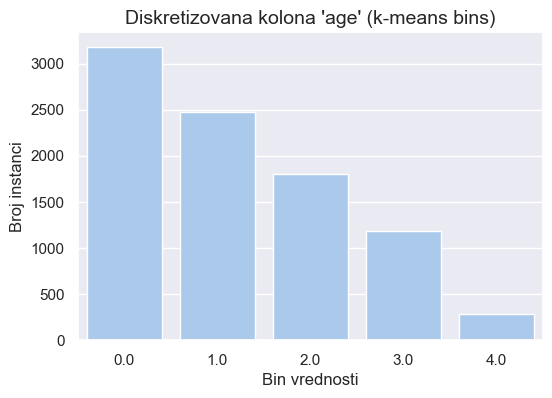

In [161]:
plt.figure(figsize=(6,4))
sns.countplot(x='age', data=X_train_age_kmeans)
plt.title("Diskretizovana kolona 'age' (k-means bins)", fontsize=14)
plt.xlabel("Bin vrednosti")
plt.ylabel("Broj instanci")
plt.show()

### Diskretizacija pomoću stabla odlučivanja

In [162]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train[['age']], y_train)

thresholds = sorted(set(tree.tree_.threshold[tree.tree_.threshold > -2]))
print("Granice koje je stablo pronašlo:", thresholds)

X_train_age_tree = X_train.copy()
X_test_age_tree = X_test.copy()

X_train_age_tree['age_bin'] = np.digitize(X_train['age'], bins=thresholds)
X_test_age_tree['age_bin'] = np.digitize(X_test['age'], bins=thresholds)

_, lr_age_tree_metrics = run_logistic_regression(X_train_age_tree, y_train, X_test_age_tree, y_test)
_, rf_age_tree_metrics = run_random_forest(X_train_age_tree, y_train, X_test_age_tree, y_test)
_, svm_age_tree_metrics = run_svm(X_train_age_tree, y_train, X_test_age_tree, y_test)
display(combine_results(lr_age_tree_metrics, rf_age_tree_metrics, svm_age_tree_metrics))

Granice koje je stablo pronašlo: [np.float64(25.5), np.float64(29.5), np.float64(58.5), np.float64(60.5), np.float64(70.5), np.float64(73.5), np.float64(89.5)]


,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.803403,0.804626,0.801098,0.801939
Random Forest,0.846843,0.846928,0.847880,0.846750
SVM (RBF),0.735334,0.739438,0.730817,0.731167


I u ovom slučaju je tačnost modela Random Forest opala za $1\%$.

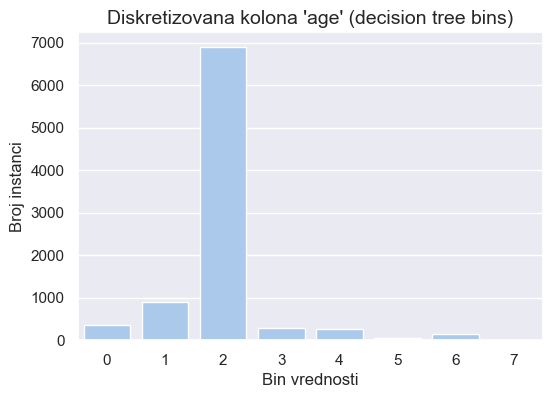

In [163]:
plt.figure(figsize=(6,4))
sns.countplot(x='age_bin', data=X_train_age_tree)
plt.title("Diskretizovana kolona 'age' (decision tree bins)", fontsize=14)
plt.xlabel("Bin vrednosti")
plt.ylabel("Broj instanci")
plt.show()

### Ručno definisanje intervala

Možemo ručno zadati granice tako da podelimo korisnike na mlađe, srednjih godina i starije.

In [164]:
bins = [0, 35, 60, 100]

X_train_age_manual3 = X_train.copy()
X_test_age_manual3 = X_test.copy()

X_train_age_manual3['age'] = pd.cut(X_train['age'], bins=bins, labels=False, include_lowest=True)
X_test_age_manual3['age'] = pd.cut(X_test['age'], bins=bins, labels=False, include_lowest=True)

_, lr_age_manual3_metrics = run_logistic_regression(X_train_age_manual3, y_train, X_test_age_manual3, y_test)
_, rf_age_manual3_metrics = run_random_forest(X_train_age_manual3, y_train, X_test_age_manual3, y_test)
_, svm_age_manual3_metrics = run_svm(X_train_age_manual3, y_train, X_test_age_manual3, y_test)
display(combine_results(lr_age_manual3_metrics, rf_age_manual3_metrics, svm_age_manual3_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.800269,0.801661,0.797837,0.798702
Random Forest,0.849978,0.850142,0.851094,0.849896
SVM (RBF),0.734438,0.738506,0.729919,0.730257


Tačnost Random Forest modela je opala za oko $1\%$.

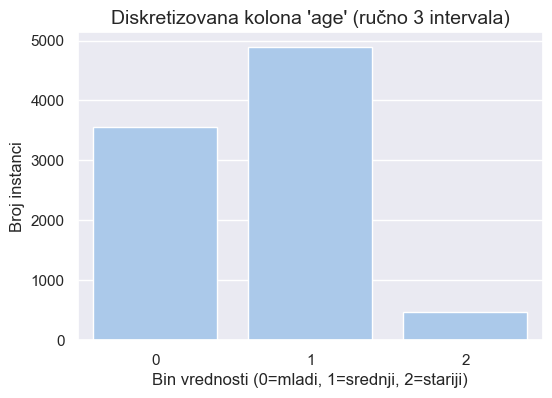

In [165]:
plt.figure(figsize=(6,4))
sns.countplot(x='age', data=X_train_age_manual3)
plt.title("Diskretizovana kolona 'age' (ručno 3 intervala)", fontsize=14)
plt.xlabel("Bin vrednosti (0=mladi, 1=srednji, 2=stariji)")
plt.ylabel("Broj instanci")
plt.show()

### Poređenje tehnika

In [166]:
discretizations = [
    ("Baseline", lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics),
    ("UniformAge", lr_age_uniform_metrics, rf_age_uniform_metrics, svm_age_uniform_metrics),
    ("QuantileAge", lr_age_quantile_metrics, rf_age_quantile_metrics, svm_age_quantile_metrics),
    ("KMeansAge", lr_age_kmeans_metrics, rf_age_kmeans_metrics, svm_age_kmeans_metrics),
    ("TreeAge", lr_age_tree_metrics, rf_age_tree_metrics, svm_age_tree_metrics),
    ("ManualAge3Bins", lr_age_manual3_metrics, rf_age_manual3_metrics, svm_age_manual3_metrics)
]

compare_metrics(discretizations)

,Encoding,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Baseline,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
1,UniformAge,0.802060,0.800539,0.853112,0.853017,0.734438,0.730257
2,QuantileAge,0.801164,0.799760,0.852217,0.852133,0.734438,0.730257
3,KMeansAge,0.801612,0.800040,0.845499,0.845380,0.734438,0.730257
4,TreeAge,0.803403,0.801939,0.846843,0.846750,0.735334,0.731167
5,ManualAge3Bins,0.800269,0.798702,0.849978,0.849896,0.734438,0.730257


Diskretizacija kolone ***age*** nije značajno promenila performanse modela jer korišćeni algoritmi (logistička regresija, Random Forest, SVM) već dobro rade sa kontinualnim numeričkim vrednostima.

## Rad sa ekstremnim vrednostima

Veliki broj ekstremnih vrednosti može da se ublaži promenom raspodele ili diskretizacijom. Ipak, u nekim situacijama je potrebno nezavisno detektovati ekstremne vrednosti i obraditi ih.

### Vizualizacija

Ekstremne vrednosti se mogu uočiti na histogramu kao stubci koji imaju visinu skoro 0 i nalaze se skroz levo ili desno. Na *box plot*-ovima se vide kao tačke koje ispadaju iz očekivanog opsega definisanog interkvartilnim rasponom. Na *scatter plot*-ovima se vide kao tačke koje značajno odstupaju od glavnog oblaka podataka.

In [167]:
def visualize_boxplots(data, num_columns, cols=3):
    n = len(num_columns)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(cols * 5, rows * 4))

    if n == 1:
        sns.boxplot(x=data[num_columns[0]])
        plt.title(f'Boxplot - {num_columns[0]}', fontsize=14)
    else:
        for i, column in enumerate(num_columns, 1):
            plt.subplot(rows, cols, i)
            sns.boxplot(x=data[column])
            plt.title(f'Boxplot - {column}', fontsize=14)

    plt.tight_layout()
    plt.show()

#### Histogram

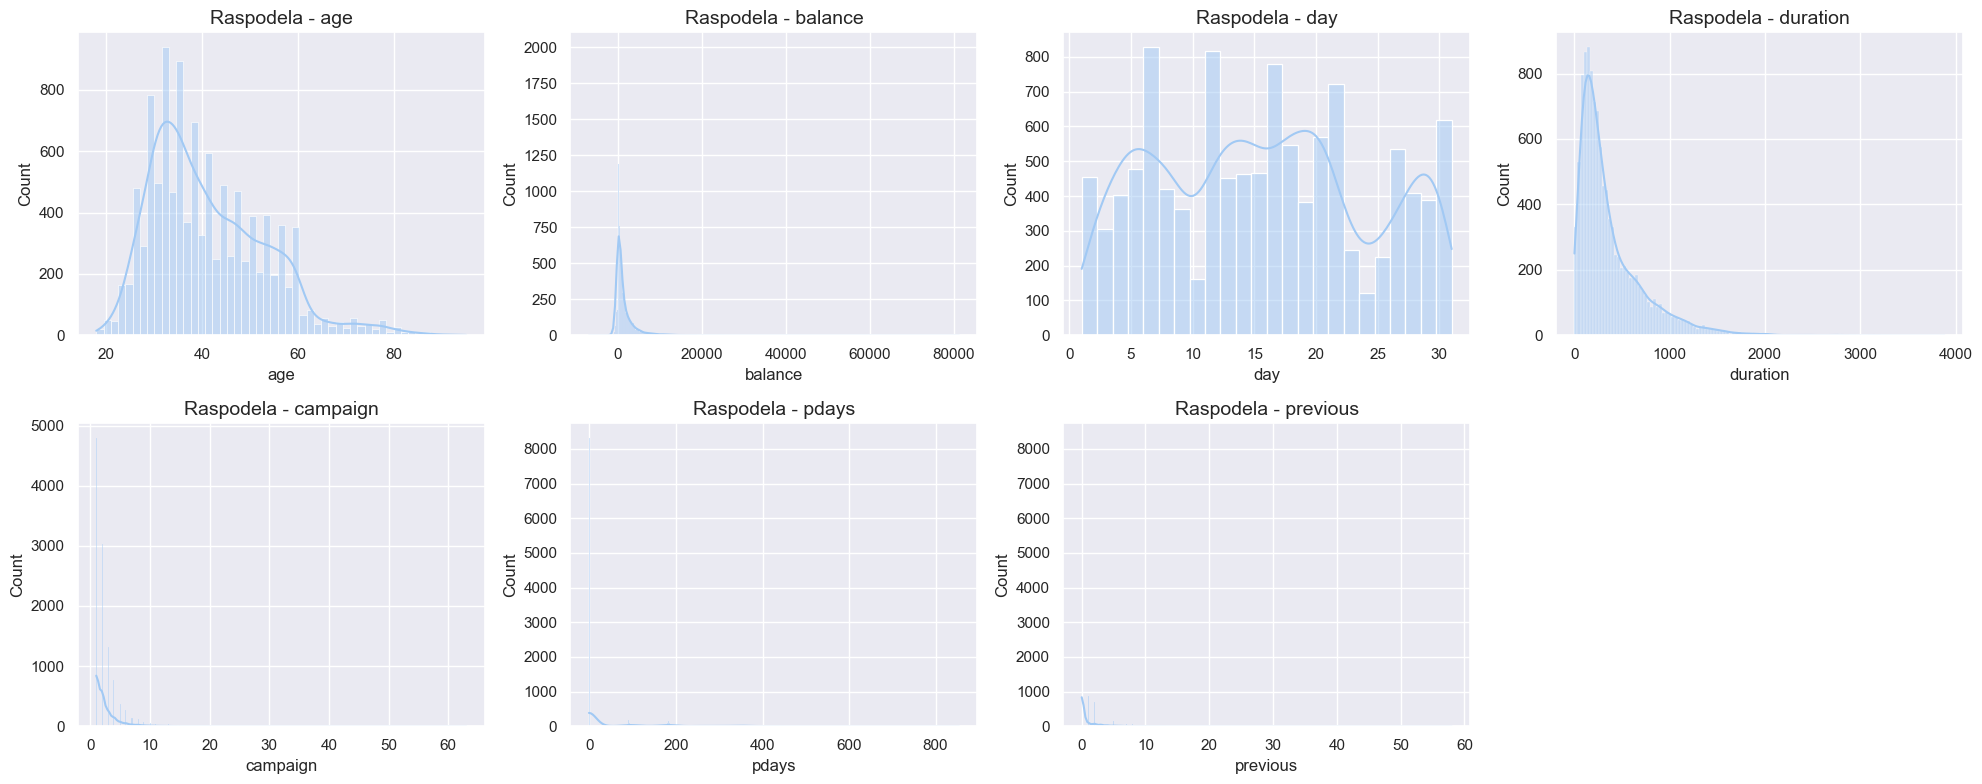

In [168]:
visualize_numerical_features(X, numeric_cols, cols=4)

#### *Box plot*

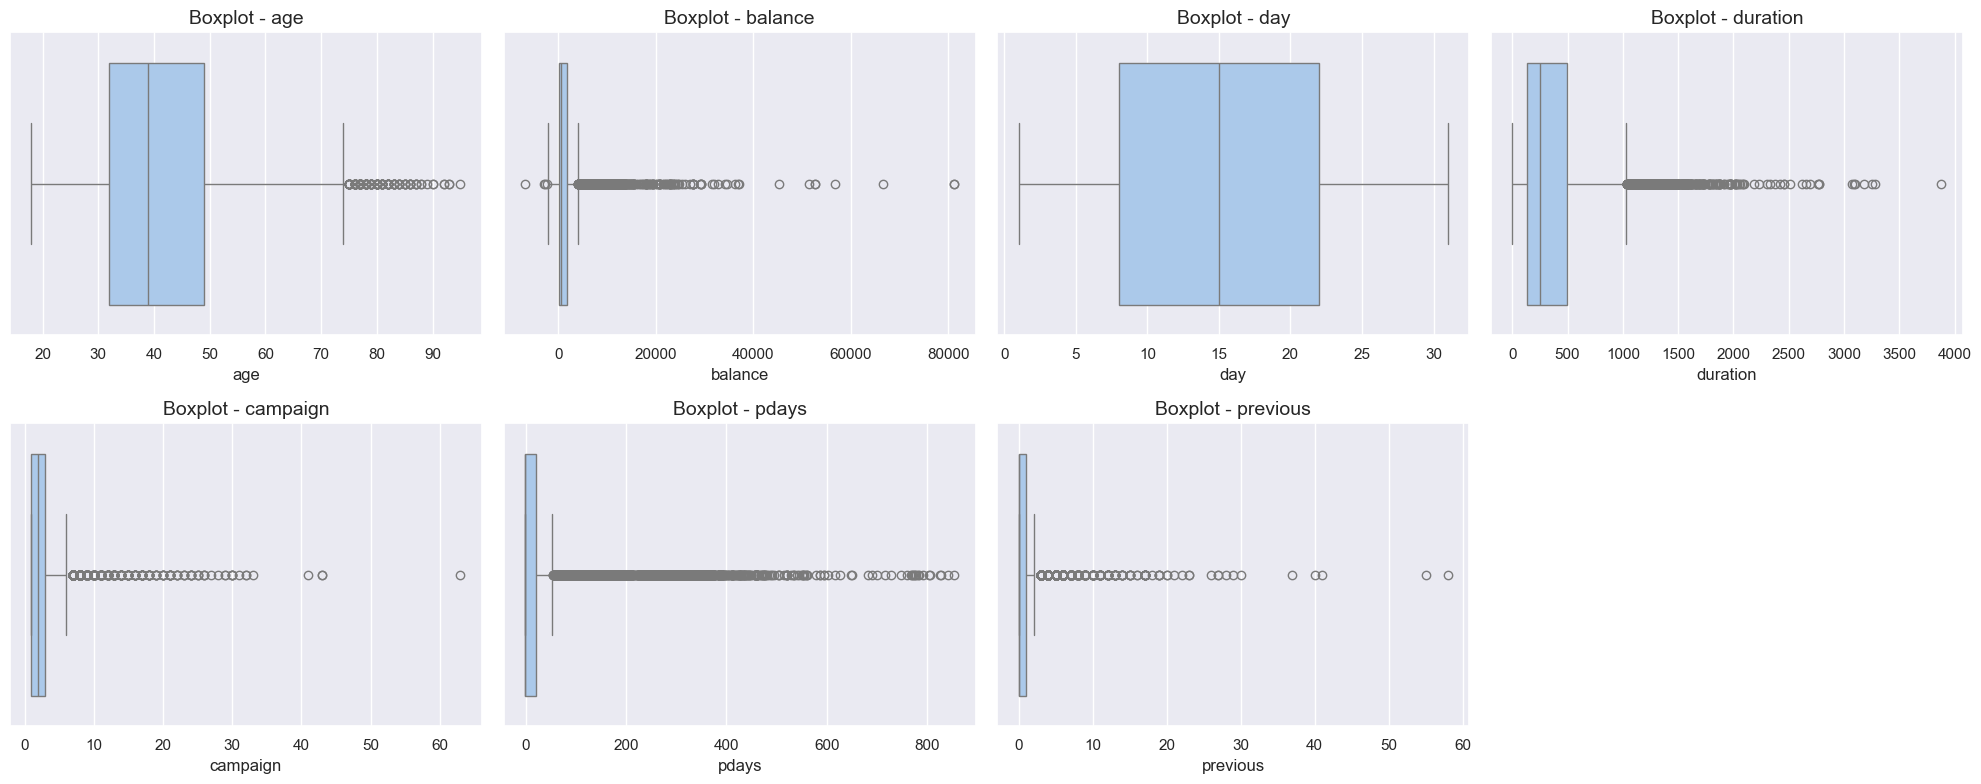

In [169]:
visualize_boxplots(X, numeric_cols, cols=4)

Vidimo da što je raspodela više iskrivljena to je veći broj ekstremnih vrednosti.

#### *Scatter plot*

In [170]:
def visualize_scatter(data, col_x, col_y, figsize=(6, 4)):
    plt.figure(figsize=figsize)
    sns.scatterplot(x=data[col_x], y=data[col_y])
    plt.title(f'Scatter plot: {col_x} vs {col_y}', fontsize=14)
    plt.xlabel(col_x)
    plt.ylabel(col_y)
    plt.show()

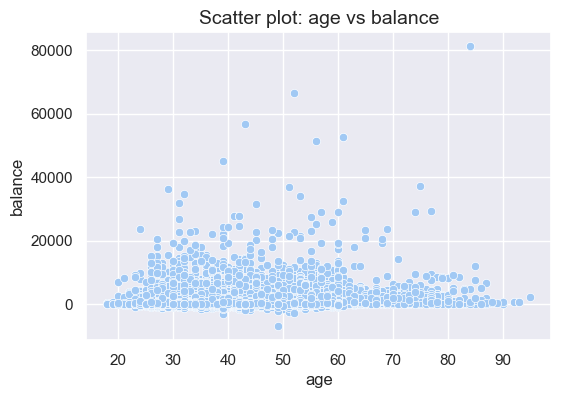

In [171]:
visualize_scatter(X, 'age', 'balance')

Vidimo da ***balance*** kod nekih korisnika može da bude izuzetno visok, što predstavlja ekstremnu vrednost.

### IQR detekcija + odsecanje na granice

In [172]:
def iqr_capping(df, columns):
    capped_df = df.copy()
    for col in columns:
        Q1 = capped_df[col].quantile(0.25)
        Q3 = capped_df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        capped_df[col] = capped_df[col].clip(lower=lower_bound, upper=upper_bound)
    
    return capped_df

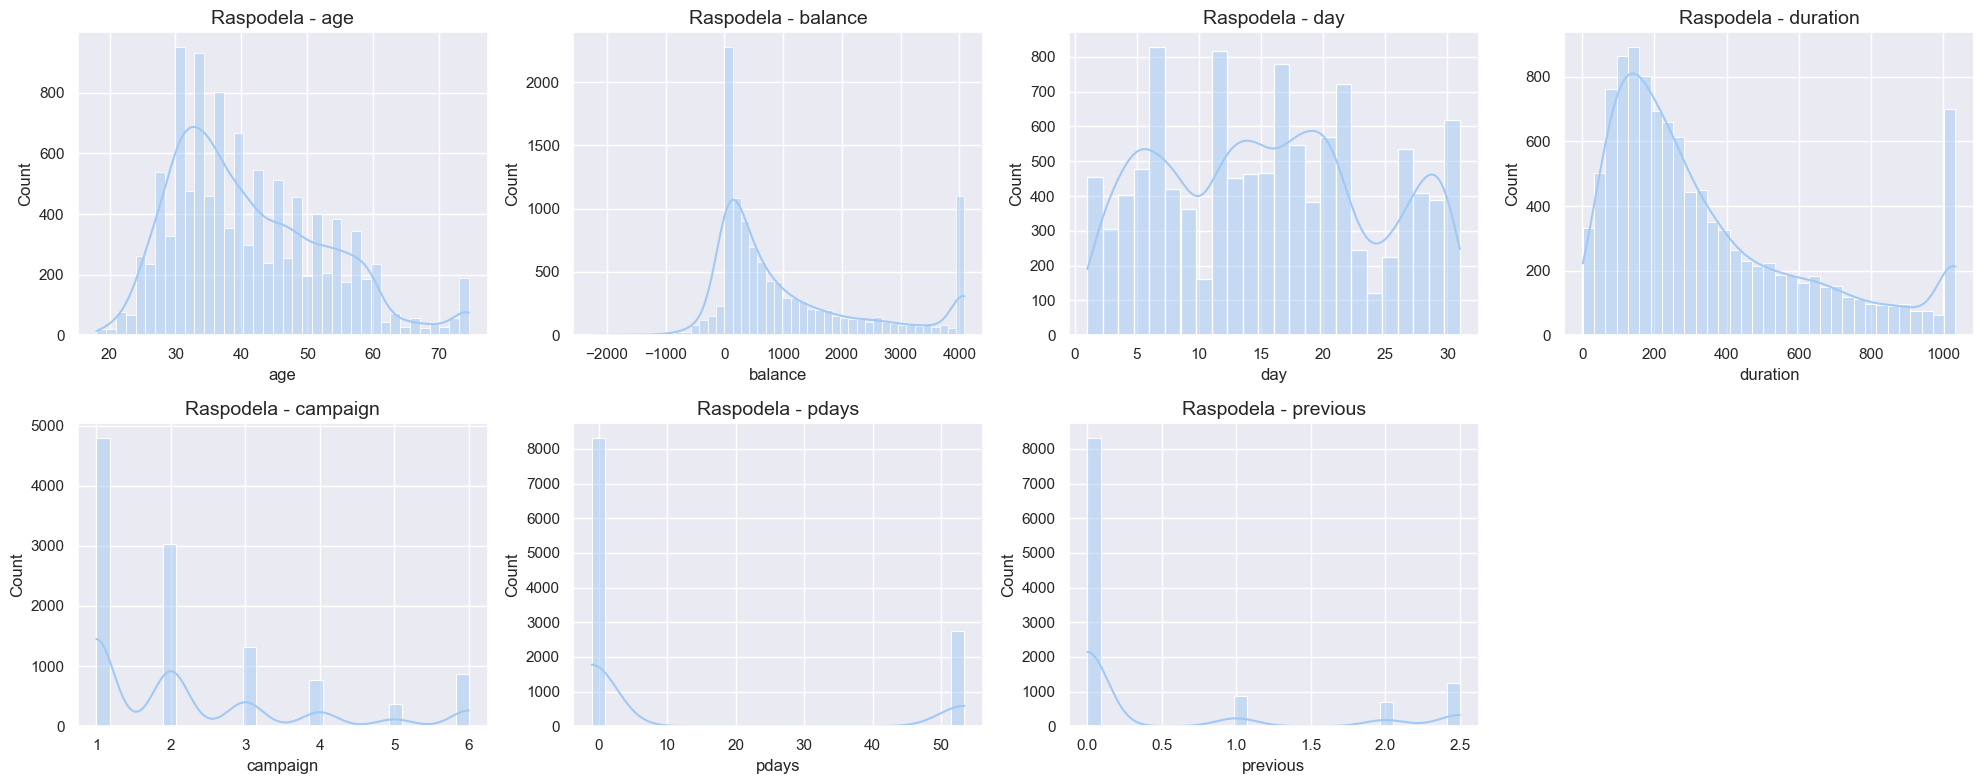

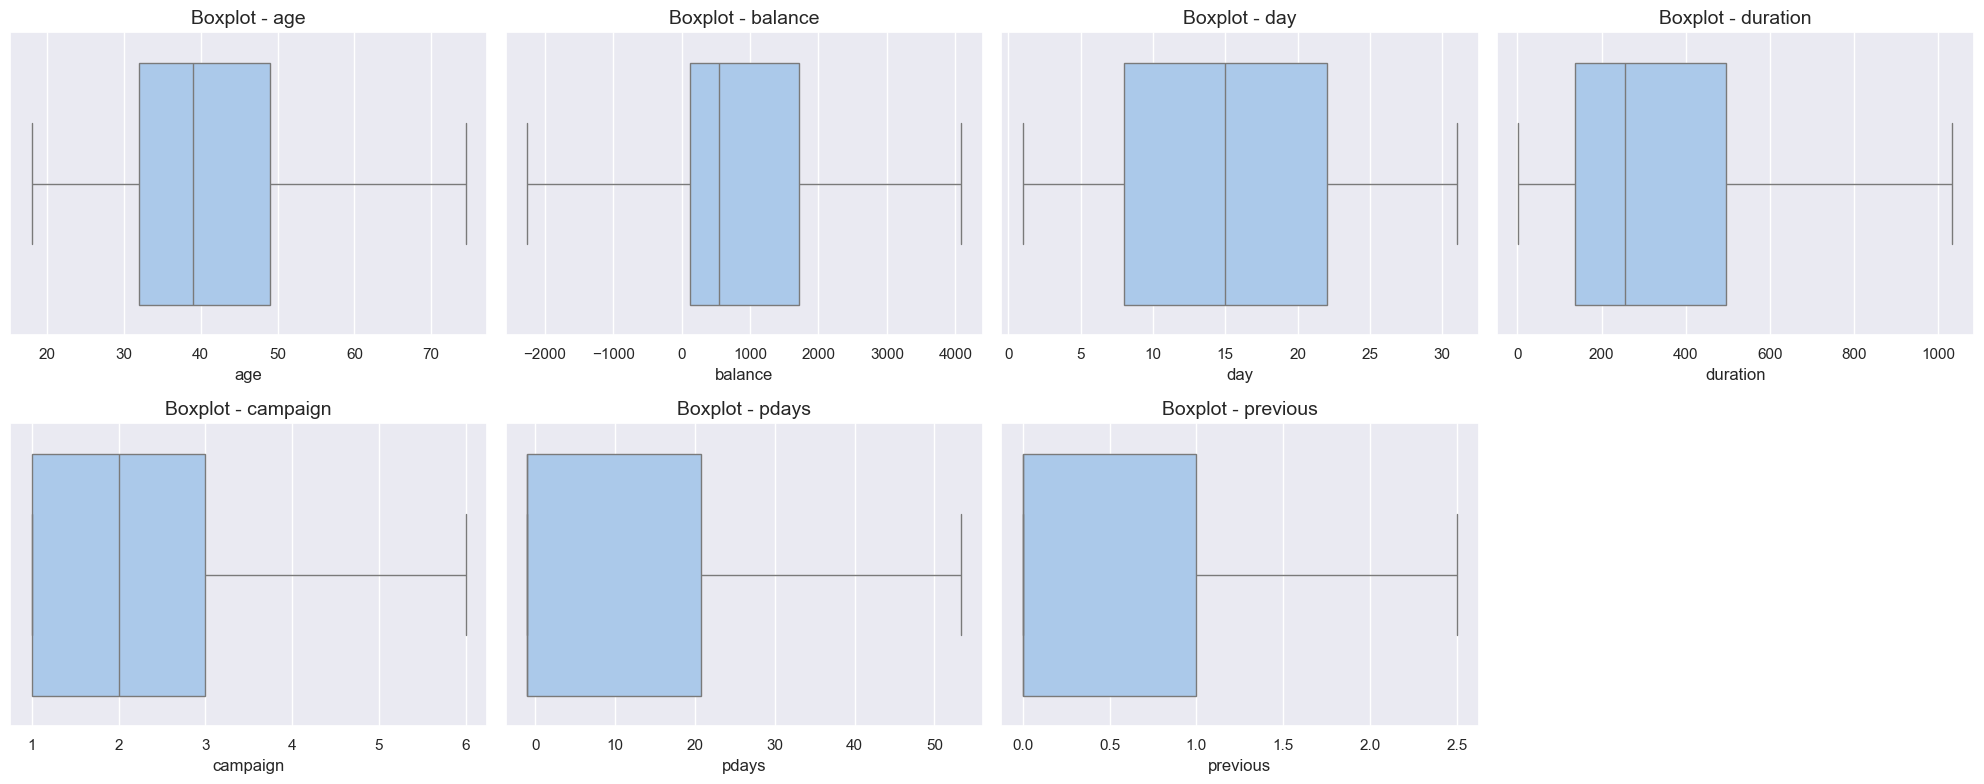

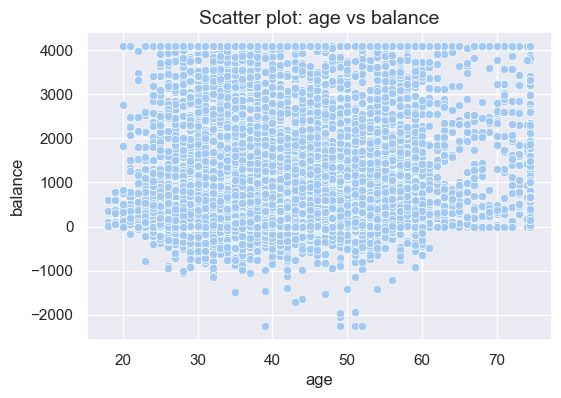

In [173]:
X_capped = iqr_capping(X, numeric_cols)

visualize_numerical_features(X_capped, numeric_cols, cols=4)
visualize_boxplots(X_capped, numeric_cols, cols=4)
visualize_scatter(X_capped, 'age', 'balance')

In [174]:
X_train, X_test, y_train, y_test = train_test_split(
    X_capped, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_iqr_capped_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_iqr_capped_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_iqr_capped_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_iqr_capped_metrics, rf_iqr_capped_metrics, svm_iqr_capped_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.808330,0.808639,0.806673,0.807277
Random Forest,0.849978,0.849745,0.850670,0.849830
SVM (RBF),0.746082,0.746050,0.743994,0.744494


Tačnost *Random Forest* algoritma je opala za manje od $1\%$, dok se tačnost SVM-a povećala za oko $1\%$.

### IQR detekcija + imputacija

In [175]:
def iqr_imputation(df, numeric_cols):
    imputed_df = df.copy()
    
    for col in numeric_cols:
        Q1 = imputed_df[col].quantile(0.25)
        Q3 = imputed_df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        imputed_df.loc[(imputed_df[col] < lower_bound) | (imputed_df[col] > upper_bound), col] = np.nan
        median_value = imputed_df[col].median()
        imputed_df[col] = imputed_df[col].fillna(median_value)
    
    return imputed_df

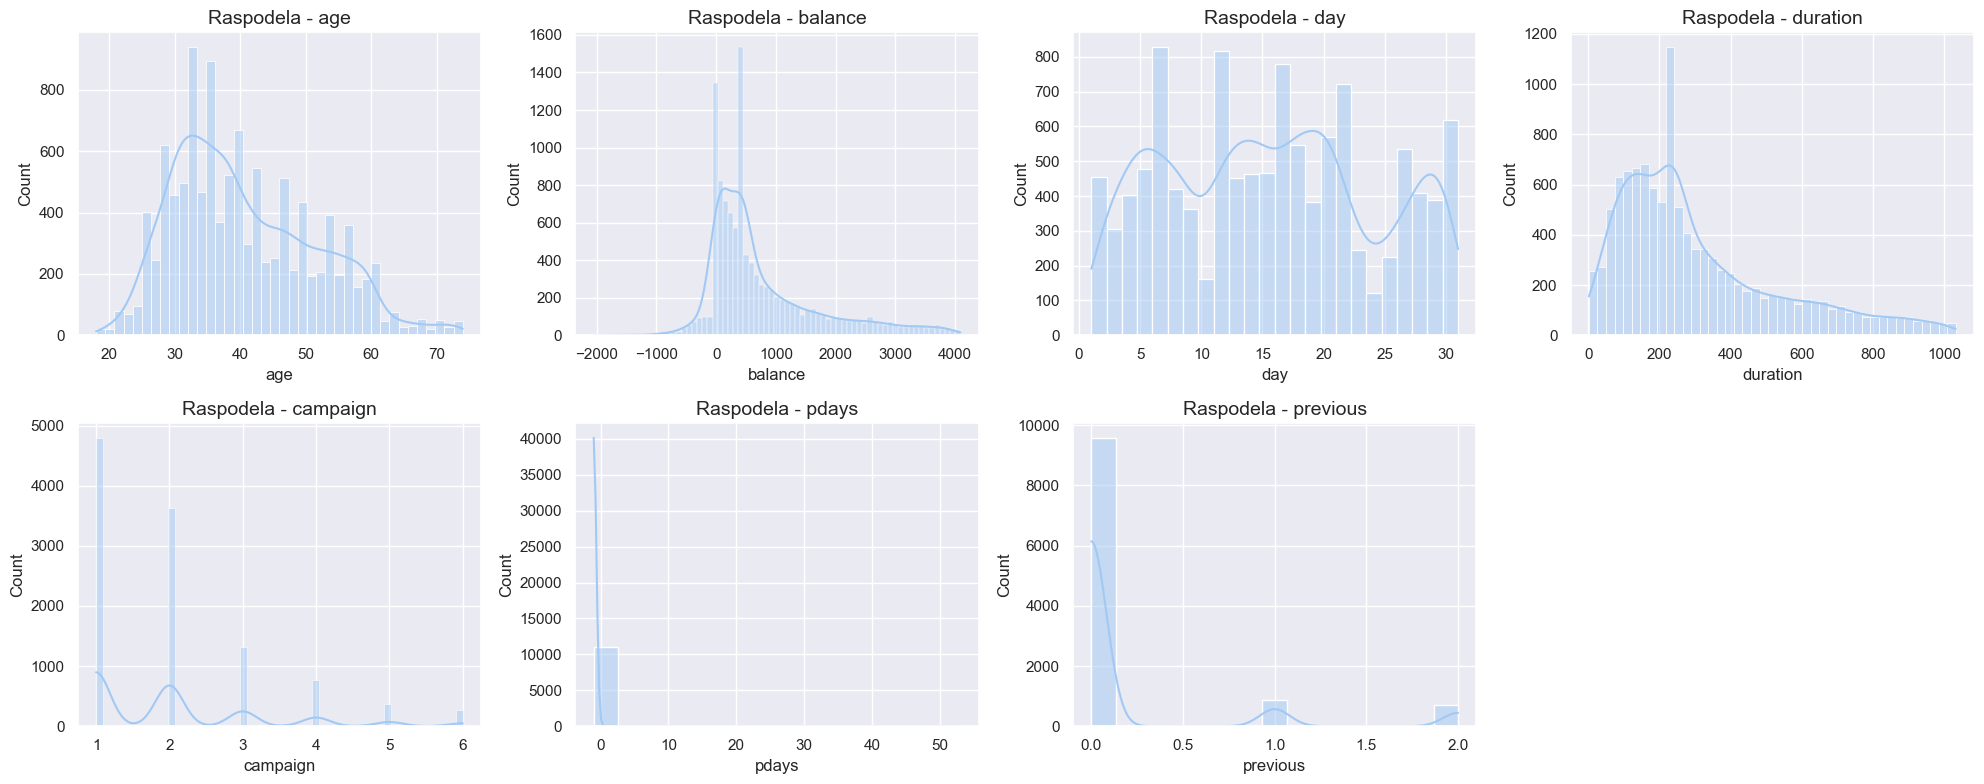

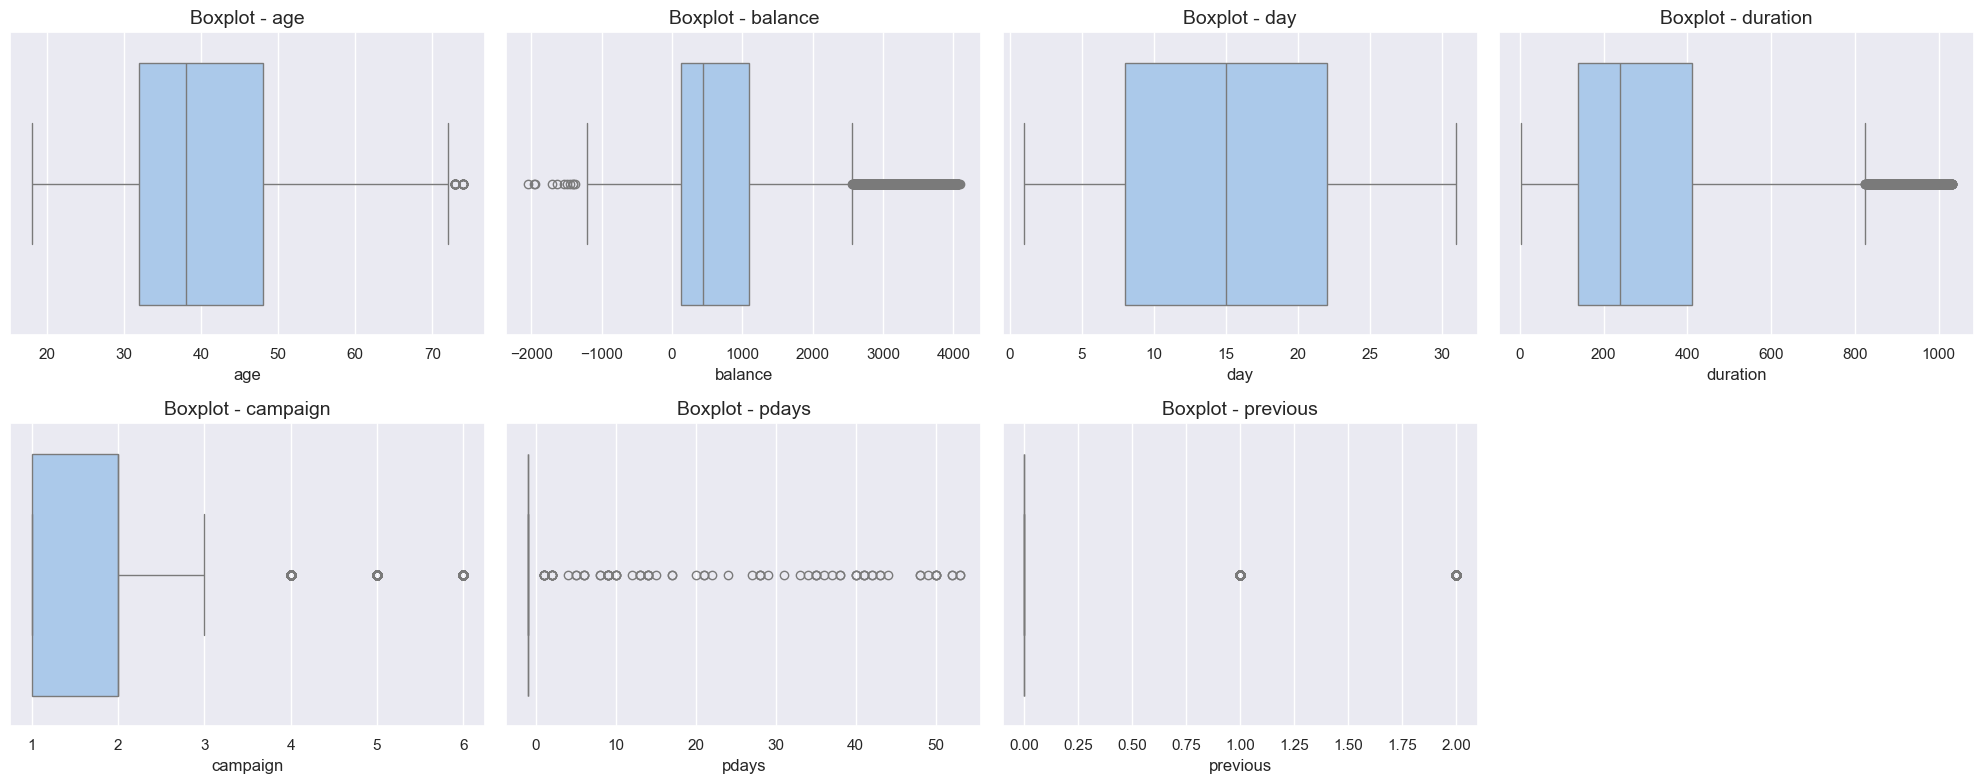

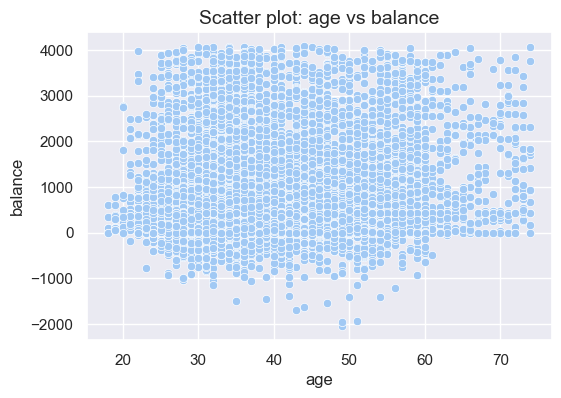

In [176]:
X_imputed = iqr_imputation(X, numeric_cols)

visualize_numerical_features(X_imputed, numeric_cols, cols=4)
visualize_boxplots(X_imputed, numeric_cols, cols=4)
visualize_scatter(X_imputed, 'age', 'balance')

In [178]:
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_iqr_impute_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_iqr_impute_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_iqr_impute_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_iqr_impute_metrics, rf_iqr_impute_metrics, svm_iqr_impute_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.770712,0.771496,0.768293,0.768986
Random Forest,0.830721,0.831086,0.831949,0.830652
SVM (RBF),0.681594,0.680764,0.679518,0.679782


Tačnost svih modela se smanjila (logistička regresija za oko $3\%$, Random Forest za $2\%$, a SVM za oko $5\%$.

### *Z-score* detekcija + *Winsorization*

In [179]:
def zscore_winsorization(df, columns, threshold=3):
    winsorized_df = df.copy()
    for col in columns:
        mean = winsorized_df[col].mean()
        std = winsorized_df[col].std()
        
        lower_bound = mean - threshold * std
        upper_bound = mean + threshold * std
        
        winsorized_df[col] = winsorized_df[col].clip(lower=lower_bound, upper=upper_bound)
    
    return winsorized_df

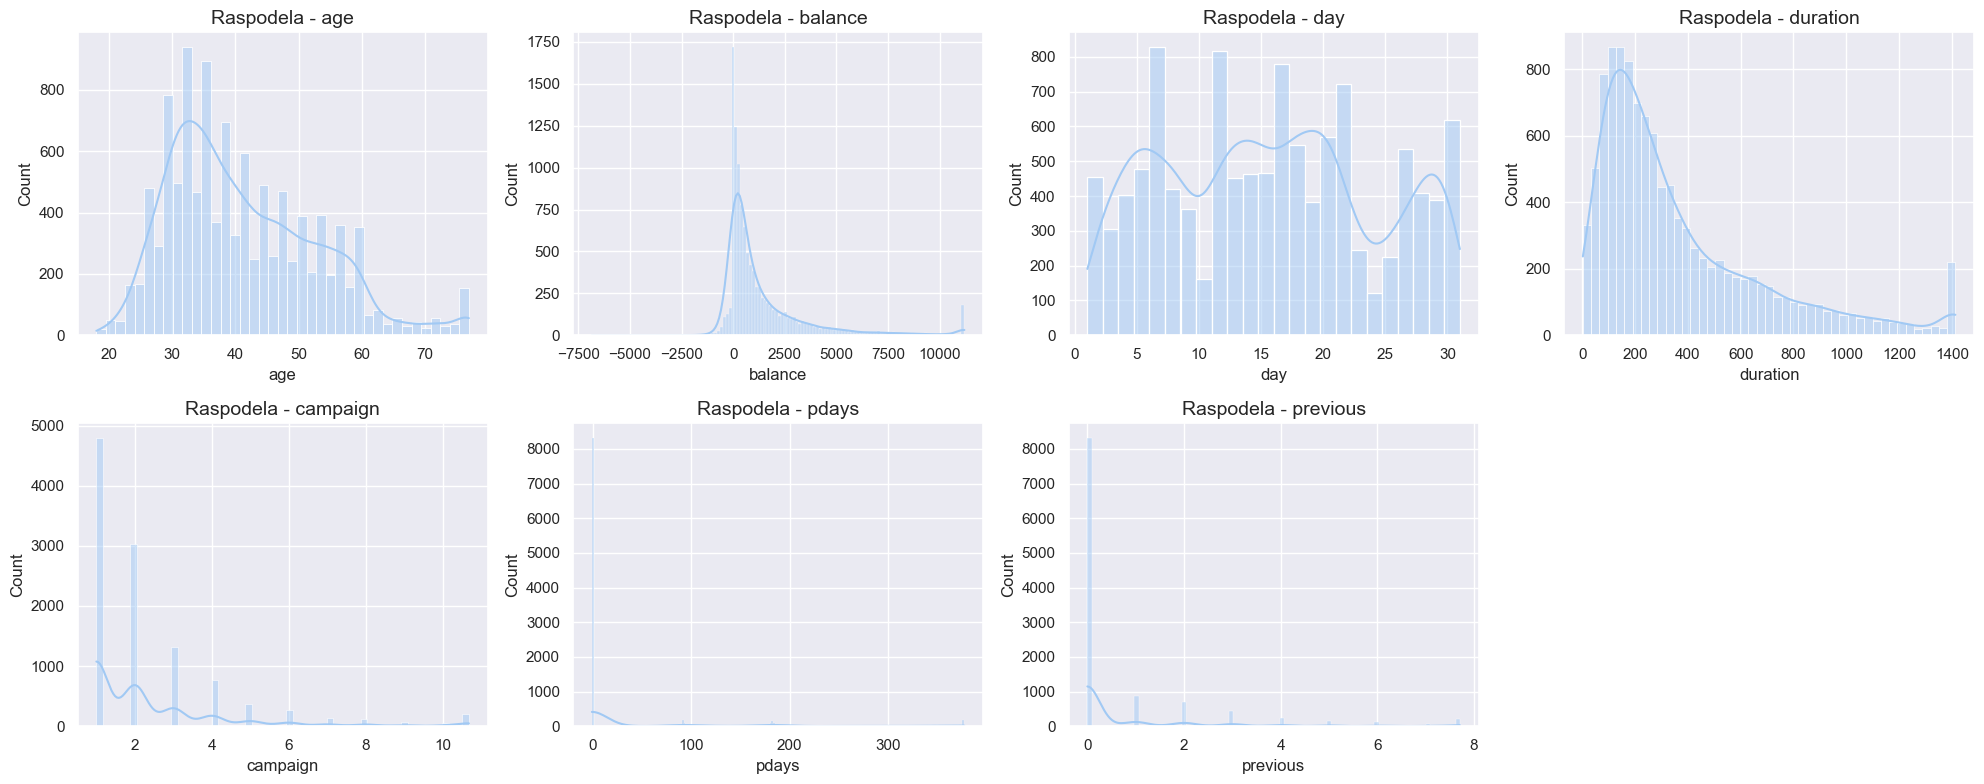

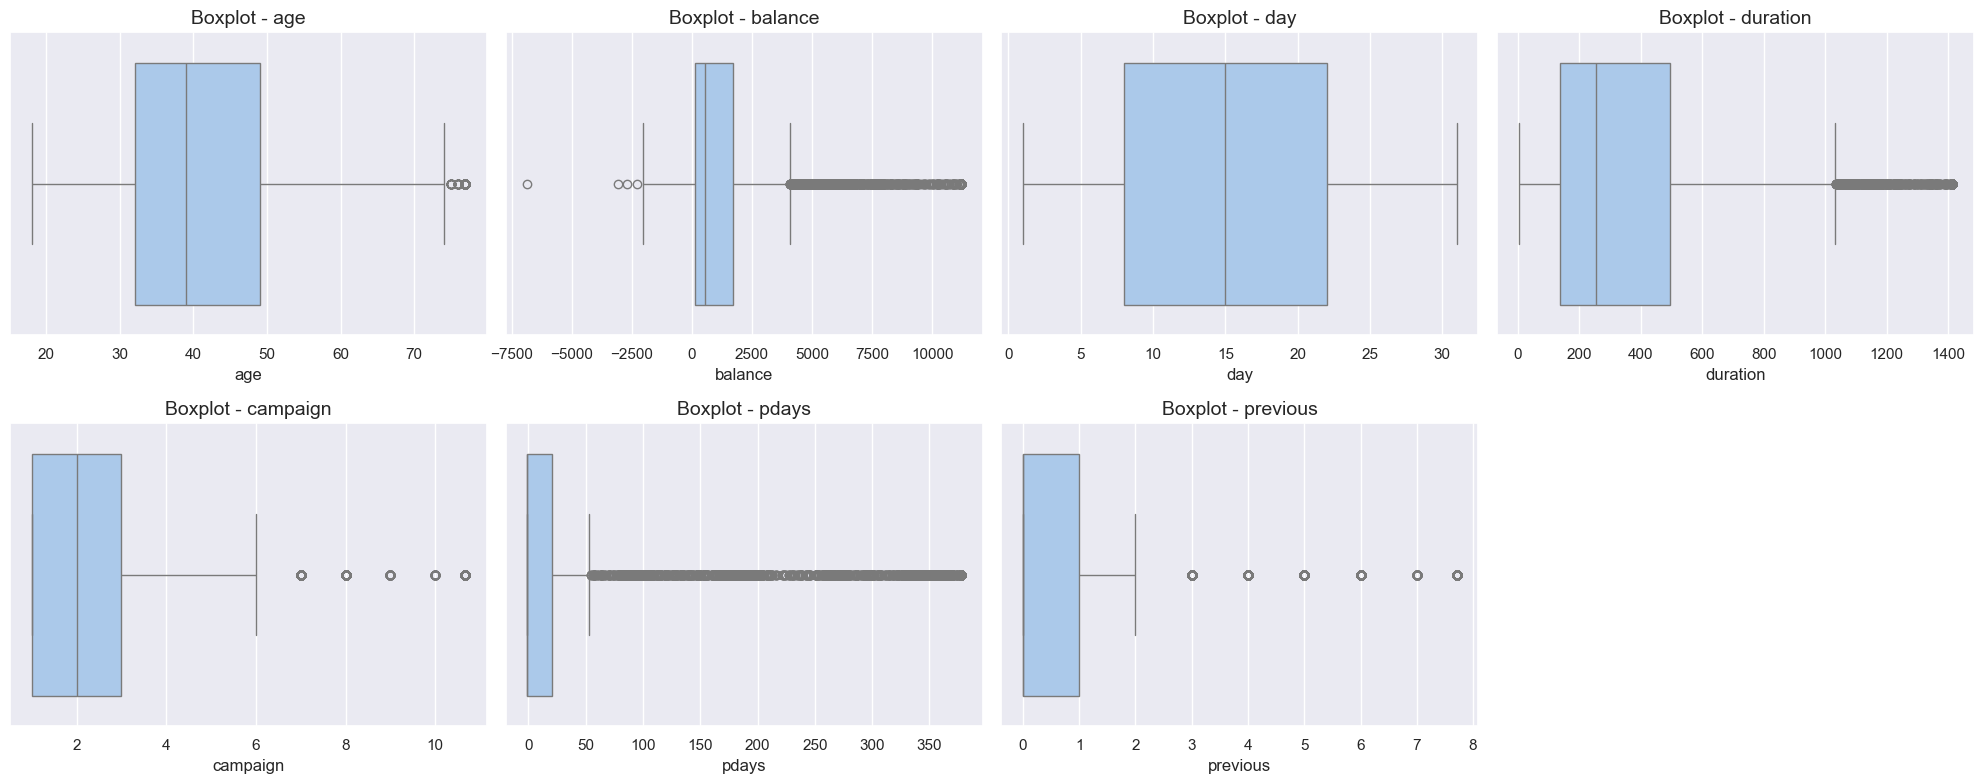

In [180]:
X_winsor = zscore_winsorization(X, numeric_cols, threshold=3)
visualize_numerical_features(X_winsor, numeric_cols, cols=4)
visualize_boxplots(X_winsor, numeric_cols, cols=4)

In [181]:
X_train, X_test, y_train, y_test = train_test_split(
    X_winsor, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_zscore_winsor_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_zscore_winsor_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_zscore_winsor_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_zscore_winsor_metrics, rf_zscore_winsor_metrics, svm_zscore_winsor_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802956,0.803738,0.800907,0.801652
Random Forest,0.852665,0.852544,0.853506,0.852543
SVM (RBF),0.737573,0.738443,0.734639,0.735209


Performanse modela su približno iste kao baseline.

### Isolation Forest + uklanjanje

In [192]:
def isolation_forest_removal(df, numeric_cols, contamination=0.05, random_state=42):
    iso = IsolationForest(contamination=contamination, random_state=random_state)
    preds = iso.fit_predict(df[numeric_cols])
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df[numeric_cols])
    
    pca = PCA(n_components=2, random_state=random_state)
    pca_result = pca.fit_transform(X_scaled)
    
    plt.figure(figsize=(8,6))
    plt.scatter(pca_result[preds == 1, 0], pca_result[preds == 1, 1],
                c="blue", label="Normal", alpha=0.6)
    plt.scatter(pca_result[preds == -1, 0], pca_result[preds == -1, 1],
                c="red", label="Outlier", alpha=0.6)
    
    plt.title("Isolation Forest Outlier Detection (PCA 2D)")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.legend()
    plt.show()
    
    # -1 označava outlier, 1 označava normalnu instancu
    mask = preds == 1
    cleaned_df = df[mask].copy()
    return cleaned_df, preds

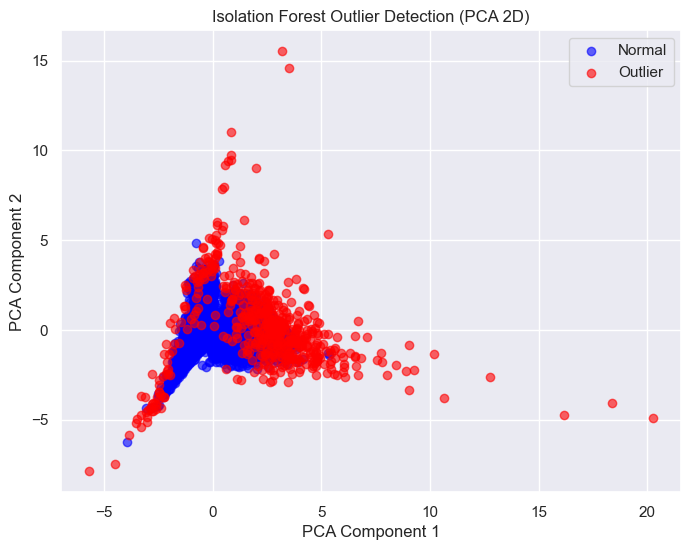

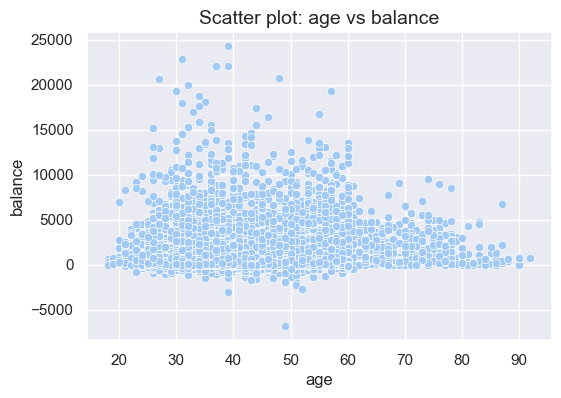

In [205]:
X_clean, preds = isolation_forest_removal(X, numeric_cols, contamination=0.05)
y_clean = y.loc[X_clean.index]
visualize_scatter(X_clean, 'age', 'balance')

In [206]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)

_, lr_isoforest_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_isoforest_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_isoforest_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_isoforest_metrics, rf_isoforest_metrics, svm_isoforest_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.809052,0.811270,0.805010,0.806534
Random Forest,0.857143,0.856754,0.858465,0.856897
SVM (RBF),0.746818,0.752366,0.739804,0.740845


Na ovaj način, samo se tačnost SVM-a povećala za oko $1\%$.

### Local Outlier Factor + uklanjanje

In [212]:
def lof_removal(df, numeric_cols, n_neighbors=20, contamination=0.05, random_state=42):
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    preds = lof.fit_predict(df[numeric_cols])  # -1 = outlier, 1 = normal
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df[numeric_cols])
    pca = PCA(n_components=2, random_state=random_state)
    pca_result = pca.fit_transform(X_scaled)
    
    plt.figure(figsize=(8,6))
    plt.scatter(pca_result[preds == 1, 0], pca_result[preds == 1, 1],
                c="blue", label="Normal", alpha=0.6)
    plt.scatter(pca_result[preds == -1, 0], pca_result[preds == -1, 1],
                c="red", label="Outlier", alpha=0.6)
    
    plt.title("Local Outlier Factor (LOF) Outlier Detection (PCA 2D, scaled data)")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.legend()
    plt.show()
    
    # -1 označava outlier, 1 označava normalnu instancu
    mask = preds == 1
    cleaned_df = df[mask].copy()
    
    return cleaned_df

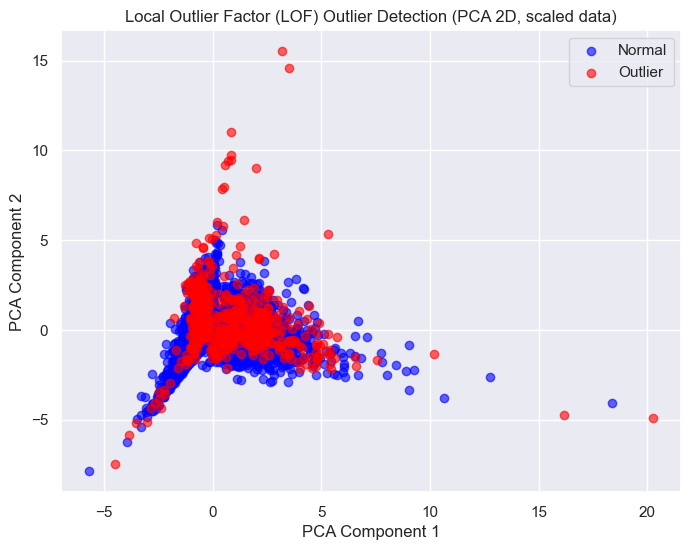

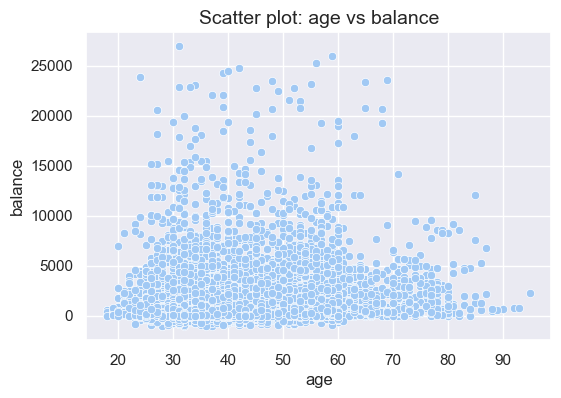

In [213]:
X_clean = lof_removal(X, numeric_cols, contamination=0.05)
y_clean = y.loc[X_clean.index]
visualize_scatter(X_clean, 'age', 'balance')

In [214]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)

_, lr_lof_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_lof_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_lof_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_lof_metrics, rf_lof_metrics, svm_lof_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802923,0.805508,0.798405,0.800033
Random Forest,0.848185,0.847297,0.848553,0.847705
SVM (RBF),0.742103,0.748134,0.734497,0.735464


U ovom slučaju, tačnost *Random Forest* algoritma se smanjila za oko $1\%$, dok se tačnost SVM-a povećala za oko $1\%$.

### Poređenje tehnika

In [215]:
outlier_methods = [
    ("Baseline", lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics),
    ("IQR + odsecanje", lr_iqr_capped_metrics, rf_iqr_capped_metrics, svm_iqr_capped_metrics),
    ("IQR + imputacija", lr_iqr_impute_metrics, rf_iqr_impute_metrics, svm_iqr_impute_metrics),
    ("ZScore + Winsorization", lr_zscore_winsor_metrics, rf_zscore_winsor_metrics, svm_zscore_winsor_metrics),
    ("IsolationForest + uklanjanje", lr_isoforest_metrics, rf_isoforest_metrics, svm_isoforest_metrics),
    ("LOF + uklanjanje", lr_lof_metrics, rf_lof_metrics, svm_lof_metrics)
]

compare_metrics(outlier_methods)

,Technique,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Baseline,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
1,IQR + odsecanje,0.808330,0.807277,0.849978,0.849830,0.746082,0.744494
2,IQR + imputacija,0.770712,0.768986,0.830721,0.830652,0.681594,0.679782
3,ZScore + Winsorization,0.802956,0.801652,0.852665,0.852543,0.737573,0.735209
4,IsolationForest + uklanjanje,0.809052,0.806534,0.857143,0.856897,0.746818,0.740845
5,LOF + uklanjanje,0.802923,0.800033,0.848185,0.847705,0.742103,0.735464


## Konstrukcija atributa

### Interakcione karakteristike

In [216]:
X_extended = X.copy()

X_extended["balance_per_age"] = X_extended["balance"] / X_extended["age"]
X_extended["total_contacts"] = X_extended["campaign"] + X_extended["previous"]

X_train, X_test, y_train, y_test = train_test_split(
    X_extended, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_construct_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_construct_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_construct_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_construct_metrics, rf_construct_metrics, svm_construct_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.802956,0.804301,0.800578,0.801441
Random Forest,0.852665,0.852884,0.853835,0.852591
SVM (RBF),0.734886,0.738909,0.730391,0.730742


Rezultati se nisu značajno promenili.

### Polinomske karakteristike

In [218]:
numeric_cols

['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

In [224]:
selected_cols = ["age", "balance", "campaign"]

X_poly = X.copy()

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly_features = poly.fit_transform(X[selected_cols])

poly_feature_names = poly.get_feature_names_out(selected_cols)
print(poly_feature_names)

X_poly = pd.concat([X_poly, pd.DataFrame(X_poly_features, columns=poly_feature_names, index=X.index)], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X_poly, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_poly_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_poly_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_poly_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_poly_metrics, rf_poly_metrics, svm_poly_metrics))

['age' 'balance' 'campaign' 'age^2' 'age balance' 'age campaign'
 'balance^2' 'balance campaign' 'campaign^2']


,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.743842,0.744758,0.740973,0.741579
Random Forest,0.837886,0.837786,0.838711,0.837757
SVM (RBF),0.539185,0.544834,0.519540,0.450282


Vidimo da su performanse modela opale značajno (logistička regresija za $6\%$, Random Forest za $2\%$, a SVM za $20\%$). Uzrok ovome može biti *overfitting* koji se može javiti kad se koriste polinomske karakteristike.

### Kreiranje vremenski zasnovanih karakteristika

In [225]:
X_time = X.copy()

# Informacija o kvartalu
X_time["quarter"] = ((X_time["month"] - 1) // 3 + 1).astype(int)

# Rani/srednji/kasni deo meseca
X_time["is_early_month"] = (X_time["day"] <= 10).astype(int)
X_time["is_mid_month"] = ((X_time["day"] > 10) & (X_time["day"] <= 20)).astype(int)
X_time["is_late_month"] = (X_time["day"] > 20).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_time, y, test_size=0.2, random_state=42, stratify=y
)

_, lr_time_metrics = run_logistic_regression(X_train, y_train, X_test, y_test)
_, rf_time_metrics = run_random_forest(X_train, y_train, X_test, y_test)
_, svm_time_metrics = run_svm(X_train, y_train, X_test, y_test)
display(combine_results(lr_time_metrics, rf_time_metrics, svm_time_metrics))

,accuracy,precision,recall,f1
Model,,,,
Logistic Regression,0.809673,0.810150,0.807902,0.808564
Random Forest,0.856247,0.856712,0.857616,0.856196
SVM (RBF),0.735334,0.739438,0.730817,0.731167


Primenom ove tehnike, rezultati se nisu značajno promenili.

### Poređenje tehnika

In [229]:
feature_constructions = [
    ("Baseline", lr_baseline_metrics, rf_baseline_metrics, svm_baseline_metrics),
    ("Interakcione karakteristike", lr_construct_metrics, rf_construct_metrics, svm_construct_metrics),
    ("Polinomske karakteristike", lr_poly_metrics, rf_poly_metrics, svm_poly_metrics),
    ("Vremenske karakteristike", lr_time_metrics, rf_time_metrics, svm_time_metrics)
]

compare_metrics(feature_constructions)

,Technique,LogReg Accuracy,LogReg F1,RF Accuracy,RF F1,SVM Accuracy,SVM F1
0,Baseline,0.802508,0.800974,0.852665,0.852591,0.735334,0.731167
1,Interakcione karakteristike,0.802956,0.801441,0.852665,0.852591,0.734886,0.730742
2,Polinomske karakteristike,0.743842,0.741579,0.837886,0.837757,0.539185,0.450282
3,Vremenske karakteristike,0.809673,0.808564,0.856247,0.856196,0.735334,0.731167
